# Bước H (phần so sánh) - dự báo qmax 1-7 ngày, 2 lõi (LSTM lstm_L2_x1_lr1e-3, Mamba mamba_L2_x1_lr1e-3) x 4 cách cấp đầu vào pha dự báo (past, hybrid, gefs, perfect) x 3 hạt giống (111, 222, 333), 30 epoch, best_model.pt theo NSE_lead_mean trung vị validation, test chấm mọi epoch. Kiểm 24 run, so các cách và hai lõi theo hạn, NPZ 7 hạn cho bộ đánh giá, hạn 1 so với mô hình một ngày C2, quá khớp theo epoch, hình, bàn giao run cho demo theo validation.
# Bài: Konold và cs., HESS 30:5067-5096 (2026). Kế hoạch: Document/01_Plan/02_Pipeline.md Mục 4.4 (bốn cách, mốc
 freeze-H, freeze-H2), 5.3 (nhiễu hạt giống), 6.1 (chỉ NSE trung vị validation dùng để chọn), 6.6 (theo hạn), 9.6 (demo).
# Hợp đồng NPZ: Workspace/06_Evaluation/01_Evaluation_LamaHCEExt/01_Evaluation_LamaHCEExt.md Mục 7.
# Notebook Kaggle "15_H_LamaHCEExt_Compare": Accelerator = None (CPU), Internet = Off, Persistence = Files only,
# Environment = Pin to original environment. Add Input (26):
   - Output 24 notebook 14_H_Train_<lõi>_L2_x1_lr1e-3_<cách>_Seed<N> (lõi lstm, mamba; cách past, hybrid, gefs, perfect;
     hạt giống 111, 222, 333), Version 1;
   - Output 13_C2_LamaHCEExt_Compare Version 1 (nhiễu B*, NSE C2 từng hạt giống, NPZ hạn 1 của C2);
   - Output 02_A3_LamaHCEExt_Benchmarks Version 1 (lịch, ID, diện tích, obs, persistence cho NPZ).
# Không cần GPU, không cần NeuralHydrology: đọc config.yml, csv chỉ số, test_results.p (pickle xarray).
# Dán nguyên tệp vào notebook rồi Save & Run All, không sửa dòng nào.

# MỤC LỤC
   Phần 1 - Tìm Output 24 run H, C2 Compare, A3; kiểm sha256, danh tính, mốc thư viện, giao thức, cấu hình
   Phần 2 - Validation của best_model.pt theo hạn: trung bình 3 hạt giống, hiệu giữa các cách và hai lõi theo nhiễu B*
   Phần 3 - Test theo hạn từ test_results.p: ghép ngày đích, NSE, KGE, PNSE từng lưu vực, kiểm khớp thư viện và obs A3
   Phần 4 - Hạn 1 so với C2 (mô hình một ngày cùng cấu hình, cùng hạt giống), cùng ngày đích; chỉ test
   Phần 5 - 168 NPZ test/S0 theo hạn cho bộ đánh giá (24 run x 7 hạn), kiểm đọc ngược và NSE tính lại
   Phần 6 - Quá khớp theo epoch và chi phí: epoch chọn, NSE_lead_mean validation/test qua 30 epoch, giờ, phút/epoch
   Phần 7 - Hình (5 hình cho báo cáo Word): NSE theo hạn (test, validation), số lưu vực NSE > 0,5, NSE và loss theo epoch
   Phần 8 - Bàn giao: mỗi (lõi, cách) một run theo validation cho demo, 24 checkpoint; h_summary, environment, manifest

lõi,cách,hạt giống,notebook,commit,trạng thái,phiên,epoch huấn luyện,model_epoch,validation,test,epoch chọn,epoch NSE_lead_mean val cao nhất,số tham số,số tham số đúng,chốt chặn: bước bỏ,giờ huấn luyện,tệp manifest,lệch sha256,lỗi
lstm,past,111,14_H_Train_lstm_L2_x1_lr1e-3_past_Seed111,6f68f47,xong,1,30,30,30,30,1,1,84414,84414,0,2.30,10,0,-
lstm,past,222,14_H_Train_lstm_L2_x1_lr1e-3_past_Seed222,6f68f47,xong,1,30,30,30,30,2,2,84414,84414,0,2.35,10,0,-
lstm,past,333,14_H_Train_lstm_L2_x1_lr1e-3_past_Seed333,6f68f47,xong,1,30,30,30,30,2,2,84414,84414,0,2.44,10,0,-
mamba,past,111,14_H_Train_mamba_L2_x1_lr1e-3_past_Seed111,6f68f47,xong,1,30,30,30,30,2,2,85111,85111,0,5.56,10,0,-
mamba,past,222,14_H_Train_mamba_L2_x1_lr1e-3_past_Seed222,6f68f47,xong,1,30,30,30,30,1,1,85111,85111,0,5.68,10,0,-
mamba,past,333,14_H_Train_mamba_L2_x1_lr1e-3_past_Seed333,6f68f47,xong,1,30,30,30,30,1,1,85111,85111,0,5.67,10,0,-
lstm,hybrid,111,14_H_Train_lstm_L2_x1_lr1e-3_hybrid_Seed111,6f68f47,xong,1,30,30,30,30,2,2,84414,84414,0,2.61,10,0,-
lstm,hybrid,222,14_H_Train_lstm_L2_x1_lr1e-3_hybrid_Seed222,6f68f47,xong,1,30,30,30,30,2,2,84414,84414,0,2.43,10,0,-
lstm,hybrid,333,14_H_Train_lstm_L2_x1_lr1e-3_hybrid_Seed333,6f68f47,xong,1,30,30,30,30,2,2,84414,84414,0,2.58,10,0,-
mamba,hybrid,111,14_H_Train_mamba_L2_x1_lr1e-3_hybrid_Seed111,6f68f47,xong,1,30,30,30,30,2,2,85111,85111,0,5.49,10,0,-


mục,giá trị,cần,đạt
Run H có đủ,24 / 24,24 (2 lõi x 4 cách x 3 hạt giống),ĐẠT
Gắn trùng một run,không,không,ĐẠT
Run không lỗi,24 / 24,tất cả,ĐẠT
Mốc thư viện theo cách,"{'past': ['6f68f47'], 'hybrid': ['6f68f47'], 'gefs': ['840450f'], 'perfect': ['6f68f47']}","{'past': '6f68f47', 'hybrid': '6f68f47', 'gefs': '840450f', 'perfect': '6f68f47'}",ĐẠT
Số nhóm pha dự báo theo cách,"{'past': 1, 'hybrid': 1, 'gefs': 8, 'perfect': 1}","past, hybrid, perfect 1; gefs 8",ĐẠT
Config giống nhau ngoài khóa riêng,0 khóa lệch,0,ĐẠT
Chốt chặn gradient: bước bỏ (tổng 24 run),0,">= 0, in ra",ĐẠT
"C2 Compare: manifest, summary, 6 NPZ hạn 1","42 / 42 tệp, complete=True","đủ, True",ĐẠT
C2 cùng cấu hình: 3 hạt giống mỗi lõi,"{'lstm': ['111', '222', '333'], 'mamba': ['111', '222', '333']}","['111', '222', '333']",ĐẠT
Ngưỡng nhiễu hạt giống (SD NSE trung vị validation B0),0.00793,> 0,ĐẠT


=> Đạt. Chạy Phần 2.


cách,lõi,epoch chọn,NSE_lead_mean,SD,SD / nhiễu,KGE_lead_mean,NSE hạn 1,NSE hạn 2,NSE hạn 3,NSE hạn 4,NSE hạn 5,NSE hạn 6,NSE hạn 7,hạn 1 - hạn 7,"C2 NSE (1 ngày, tham khảo)"
past,lstm,1/2/2,0.2028,0.0070,0.8854,0.2054,0.5199,0.2556,0.1760,0.1399,0.1167,0.1020,0.0878,0.4322,0.7677
past,mamba,2/1/1,0.1833,0.0196,2.4748,0.2226,0.5268,0.2528,0.1675,0.1162,0.0862,0.0686,0.0600,0.4668,0.7630
hybrid,lstm,2/2/2,0.2455,0.0085,1.0660,0.2808,0.6321,0.3988,0.2194,0.1573,0.1291,0.1093,0.0924,0.5397,0.7677
hybrid,mamba,2/1/1,0.2292,0.0072,0.9126,0.2669,0.6118,0.3765,0.2121,0.1437,0.1089,0.0844,0.0690,0.5428,0.7630
gefs,lstm,2/5/3,0.4414,0.0092,1.1642,0.4806,0.6685,0.5368,0.4808,0.4302,0.3810,0.3233,0.2791,0.3894,0.7677
gefs,mamba,3/2/2,0.4421,0.0049,0.6165,0.5001,0.6872,0.5649,0.4976,0.4406,0.3679,0.3057,0.2455,0.4417,0.7630
perfect,lstm,9/5/9,0.7000,0.0043,0.5411,0.7270,0.7544,0.7045,0.6967,0.6903,0.6867,0.6815,0.6764,0.0780,0.7677
perfect,mamba,8/7/8,0.7082,0.0085,1.0750,0.7324,0.7619,0.7153,0.7044,0.6985,0.6920,0.6883,0.6831,0.0788,0.7630


so sánh,A,B,chỉ số,A - B,bội nhiễu,hạt giống cùng dấu,trong nhiễu
cách (lstm),hybrid,past,NSE_lead_mean,0.0427,5.3782,3/3,không
cách (lstm),gefs,hybrid,NSE_lead_mean,0.1959,24.6917,3/3,không
cách (lstm),gefs,past,NSE_lead_mean,0.2385,30.0699,3/3,không
cách (lstm),perfect,gefs,NSE_lead_mean,0.2587,32.6119,3/3,không
cách (mamba),hybrid,past,NSE_lead_mean,0.0459,5.7820,3/3,không
cách (mamba),gefs,hybrid,NSE_lead_mean,0.2129,26.8422,3/3,không
cách (mamba),gefs,past,NSE_lead_mean,0.2588,32.6242,3/3,không
cách (mamba),perfect,gefs,NSE_lead_mean,0.2661,33.5406,3/3,không
lõi (past),mamba,lstm,NSE_lead_mean,-0.0195,-2.4576,3/3,không
lõi (hybrid),mamba,lstm,NSE_lead_mean,-0.0163,-2.0538,2/3,không


lõi,cách,hạt giống,epoch chọn,lưu vực có NSE_lead_mean,NSE_lead_mean,KGE_lead_mean,NSE_lead1,NSE_lead2,NSE_lead3,NSE_lead4,NSE_lead5,NSE_lead6,NSE_lead7,khớp summary
lstm,past,111,1,451,0.1949,0.2157,0.5008,0.2468,0.1658,0.1330,0.1068,0.0952,0.0782,True
lstm,past,222,2,451,0.2053,0.1914,0.5203,0.2590,0.1792,0.1427,0.1192,0.1024,0.0885,True
lstm,past,333,2,451,0.2083,0.2090,0.5387,0.2609,0.1830,0.1439,0.1242,0.1085,0.0965,True
mamba,past,111,2,451,0.1638,0.2005,0.5260,0.2313,0.1418,0.1004,0.0724,0.0587,0.0573,True
mamba,past,222,1,451,0.1831,0.2606,0.5176,0.2571,0.1694,0.1158,0.0823,0.0581,0.0450,True
mamba,past,333,1,451,0.2031,0.2066,0.5367,0.2701,0.1913,0.1324,0.1039,0.0890,0.0777,True
lstm,hybrid,111,2,451,0.2499,0.2938,0.6453,0.4050,0.2198,0.1591,0.1328,0.1150,0.0977,True
lstm,hybrid,222,2,451,0.2357,0.2780,0.6103,0.3832,0.2145,0.1546,0.1286,0.1027,0.0836,True
lstm,hybrid,333,2,451,0.2508,0.2706,0.6408,0.4081,0.2240,0.1581,0.1259,0.1103,0.0959,True
mamba,hybrid,111,2,451,0.2239,0.2533,0.6431,0.3834,0.2152,0.1459,0.1039,0.0831,0.0687,True


... (17 outputs left out)

cách,giờ huấn luyện Mamba / LSTM,phút huấn luyện/epoch Mamba / LSTM,phút validation/lượt Mamba / LSTM
past,2.38,2.64,1.80
hybrid,2.25,2.52,1.64
gefs,2.27,2.60,1.60
perfect,2.30,2.54,1.77


Tổng giờ huấn luyện 24 run: 98.1 giờ (LSTM 29.7, Mamba 68.4); giờ phiên Kaggle: 125.3


mục,giá trị,cần,đạt
Đường theo epoch đủ 30 epoch x 24 run,720,720,ĐẠT
"Đường không NaN ở NSE_lead_mean validation, test, loss huấn luyện, loss validation",0,0,ĐẠT
Có giờ huấn luyện mọi run,24,24,ĐẠT


=> Đạt. Chạy Phần 7.


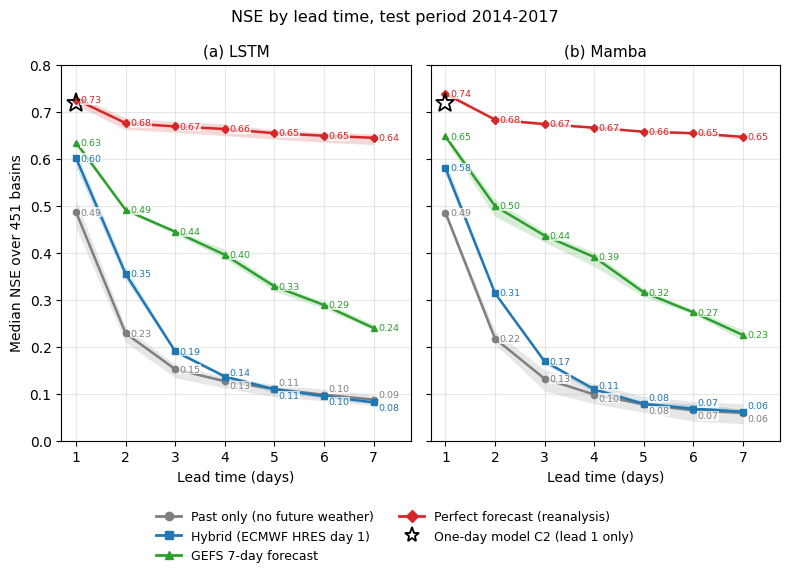

Hình: NSE trung vị qua 451 lưu vực trên test 2014-2017 theo hạn dự báo 1-7 ngày, (a) LSTM, (b) Mamba; mỗi đường là một cách cấp thông tin thời tiết các ngày tới, trung bình 3 hạt giống, dải mờ là khoảng 3 hạt giống; số cạnh mỗi điểm là giá trị đó; sao rỗng là mô hình một ngày C2 cùng cấu hình (chỉ có hạn 1). NSE LSTM từ hạn 1 tới hạn 7: chỉ quá khứ 0,49 => 0,09, lai 0,60 => 0,08, GEFS 0,63 => 0,24, hoàn hảo 0,73 => 0,64. Persistence (Q đo ngày trước ngày phát dự báo) không vẽ: NSE 0,35 ở hạn 1, âm từ hạn 2 (-0,15) tới -0,51 ở hạn 7 (bảng H_test_summary.csv).



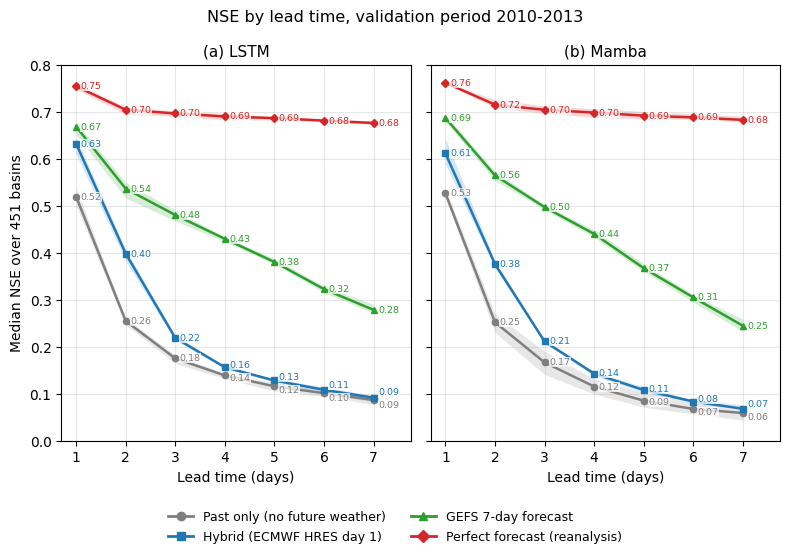

Hình: Như hình NSE test nhưng trên validation 2010-2013 (kỳ dùng để chọn và so mô hình), cùng thang trục dọc. NSE trung bình 7 hạn LSTM / Mamba: chỉ quá khứ 0,203 / 0,183, lai 0,245 / 0,229, GEFS 0,441 / 0,442, hoàn hảo 0,700 / 0,708. Hiệu Mamba - LSTM trung bình 7 hạn (bội nhiễu hạt giống 0,0079; số hạn có |hiệu| vượt 1 nhiễu): chỉ quá khứ -0,0171 (-2,2; 5/7), lai -0,0189 (-2,4; 6/7), GEFS 0,0014 (0,2; 7/7), hoàn hảo 0,0076 (1,0; 2/7); dương là Mamba tốt hơn. Hai lõi gần như trùng đường vì hiệu nhỏ so với khoảng cách giữa các cách.



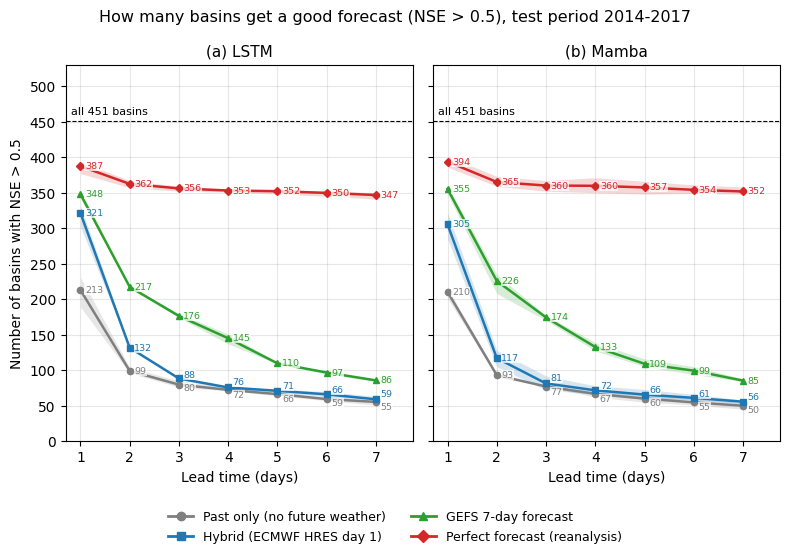

Hình: Số lưu vực (trong 451 lưu vực có NSE) có dự báo tốt, tức NSE test > 0,5 (mức 'đạt' thường dùng trong thủy văn, Moriasi và cs., 2007), theo hạn, (a) LSTM, (b) Mamba; đường đứt ngang là toàn bộ 451 lưu vực; đường là trung bình 3 hạt giống, dải là khoảng 3 hạt giống, số cạnh mỗi điểm là số lưu vực. Hình NSE theo hạn cho biết lưu vực đứng giữa đạt bao nhiêu; hình này đếm thẳng bao nhiêu lưu vực còn dự báo dùng được. LSTM hạn 1 => hạn 7: chỉ quá khứ 213 => 55, lai 321 => 59, GEFS 348 => 86, hoàn hảo 387 => 347; Mamba hạn 7: chỉ quá khứ 50, lai 56, GEFS 85, hoàn hảo 352.



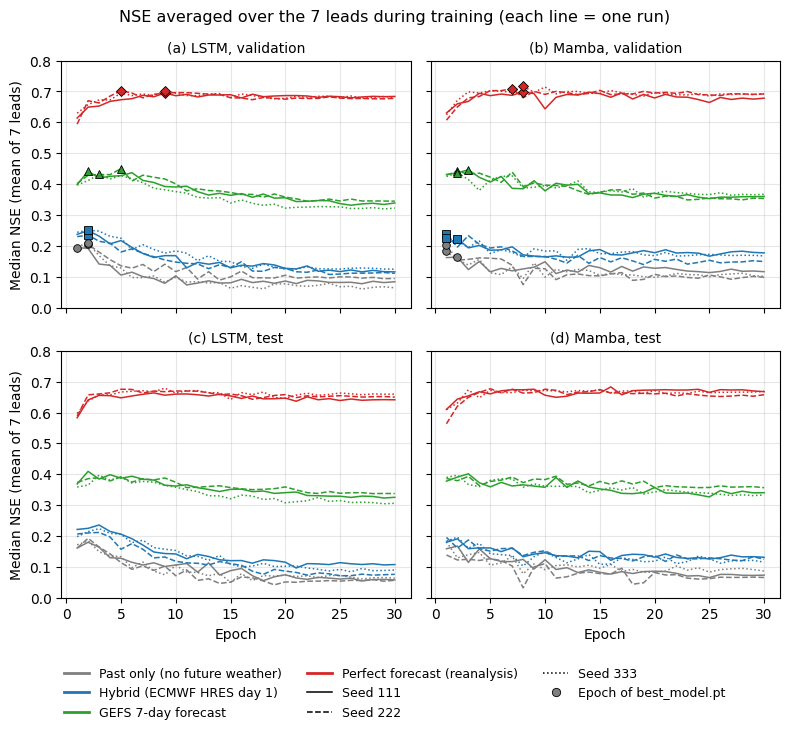

Hình: NSE trung vị qua 451 lưu vực (trung bình 7 hạn) theo epoch; hàng trên validation, hàng dưới test; cột trái LSTM, cột phải Mamba; mỗi đường là một run (màu theo cách, kiểu nét theo hạt giống), ký hiệu viền đen là epoch của best_model.pt từng hạt giống (chọn theo validation); cùng thang trục dọc với hình NSE theo hạn. Khi thiếu thông tin thời tiết các ngày tới (chỉ quá khứ, lai, GEFS), NSE cao nhất ở vài epoch đầu rồi giảm (validation LSTM từ epoch chọn tới epoch 30 giảm 0,121, 0,128, 0,106); với dự báo hoàn hảo chỉ giảm 0,019. best_model.pt chọn theo validation nên không chịu phần giảm này. Dao động validation giữa hai epoch liền nhau (trung vị, LSTM / Mamba): chỉ quá khứ 0,007 / 0,007, lai 0,007 / 0,007, GEFS 0,006 / 0,007, hoàn hảo 0,004 / 0,007; chênh lớn nhất giữa 3 hạt giống ở cùng epoch: chỉ quá khứ 0,062 / 0,051, lai 0,047 / 0,048, GEFS 0,036 / 0,056, hoàn hảo 0,035 / 0,071.



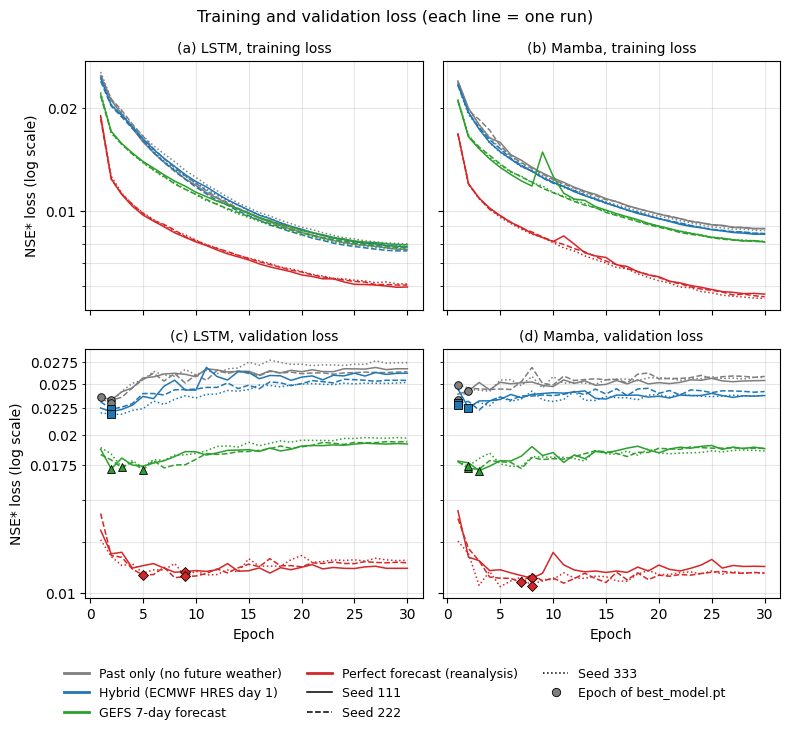

Hình: Loss NSE* (trung bình 7 hạn) theo epoch, trục dọc log; hàng trên kỳ huấn luyện, hàng dưới validation; cột trái LSTM, cột phải Mamba; mỗi đường là một run, ký hiệu viền đen là epoch của best_model.pt (chọn theo NSE validation, không theo loss nên có thể không trùng điểm loss thấp nhất). Tỉ số loss epoch 30 / epoch chọn (trung bình 3 hạt giống, LSTM / Mamba), huấn luyện: chỉ quá khứ 0,35 / 0,39, lai 0,38 / 0,39, GEFS 0,51 / 0,50, hoàn hảo 0,68 / 0,65; validation: chỉ quá khứ 1,15 / 1,06, lai 1,16 / 1,05, GEFS 1,13 / 1,09, hoàn hảo 1,05 / 1,05. Tỉ số huấn luyện dưới 1 và validation trên 1 nghĩa là mô hình khớp kỳ huấn luyện tốt hơn trong khi validation kém đi (quá khớp).

=> 5 hình ở h_compare/Figures/. Chạy Phần 8.


cách,lõi,hạt giống,epoch chọn,NSE_lead_mean val,cách hạt giống thứ hai,hòa,NSE_lead_mean test (báo cáo),notebook
past,lstm,333,2,0.2083,0.0030,False,0.1847,14_H_Train_lstm_L2_x1_lr1e-3_past_Seed333
past,mamba,333,1,0.2031,0.0200,False,0.1816,14_H_Train_mamba_L2_x1_lr1e-3_past_Seed333
hybrid,lstm,333,2,0.2508,0.0009,False,0.2147,14_H_Train_lstm_L2_x1_lr1e-3_hybrid_Seed333
hybrid,mamba,222,1,0.2375,0.0112,False,0.1960,14_H_Train_mamba_L2_x1_lr1e-3_hybrid_Seed222
gefs,lstm,222,5,0.4504,0.0085,False,0.3920,14_H_Train_lstm_L2_x1_lr1e-3_gefs_Seed222
gefs,mamba,111,3,0.4468,0.0043,False,0.4017,14_H_Train_mamba_L2_x1_lr1e-3_gefs_Seed111
perfect,lstm,222,5,0.7026,0.0001,False,0.6753,14_H_Train_lstm_L2_x1_lr1e-3_perfect_Seed222
perfect,mamba,333,8,0.7163,0.0075,False,0.6721,14_H_Train_mamba_L2_x1_lr1e-3_perfect_Seed333


lõi,cách,hạt giống,notebook,thư mục run,epoch chọn,library_commit,forecast_input_mode,số tham số,demo,sha256 best_model.pt,sha256 config.yml,sha256 train_data_scaler.yml,NPZ
lstm,past,111,14_H_Train_lstm_L2_x1_lr1e-3_past_Seed111,h_runs/H_lstm_L2_x1_lr1e-3_past_seed111_1411_112039,1,6f68f471bec255f67d446acd6c6556358ff9bfea,none,84414,False,0c971ebece4a,8485f4a5463a,baae107de375,contracts/SF_lstm_L2_x1_lr1e-3_Hpast_seed111_test_S0_lead{1..7}.npz
lstm,past,222,14_H_Train_lstm_L2_x1_lr1e-3_past_Seed222,h_runs/H_lstm_L2_x1_lr1e-3_past_seed222_1411_085648,2,6f68f471bec255f67d446acd6c6556358ff9bfea,none,84414,False,4ab3dd93b4e2,e1adec1a323b,baae107de375,contracts/SF_lstm_L2_x1_lr1e-3_Hpast_seed222_test_S0_lead{1..7}.npz
lstm,past,333,14_H_Train_lstm_L2_x1_lr1e-3_past_Seed333,h_runs/H_lstm_L2_x1_lr1e-3_past_seed333_1411_102936,2,6f68f471bec255f67d446acd6c6556358ff9bfea,none,84414,True,21239fce5aa2,aabaaef84289,baae107de375,contracts/SF_lstm_L2_x1_lr1e-3_Hpast_seed333_test_S0_lead{1..7}.npz
mamba,past,111,14_H_Train_mamba_L2_x1_lr1e-3_past_Seed111,h_runs/H_mamba_L2_x1_lr1e-3_past_seed111_1411_102602,2,6f68f471bec255f67d446acd6c6556358ff9bfea,none,85111,False,493c17dacc2b,64e9a2cc5f01,baae107de375,contracts/SF_mamba_L2_x1_lr1e-3_Hpast_seed111_test_S0_lead{1..7}.npz
mamba,past,222,14_H_Train_mamba_L2_x1_lr1e-3_past_Seed222,h_runs/H_mamba_L2_x1_lr1e-3_past_seed222_1411_100817,1,6f68f471bec255f67d446acd6c6556358ff9bfea,none,85111,False,52f2856c6315,0cd5fb2e5d45,baae107de375,contracts/SF_mamba_L2_x1_lr1e-3_Hpast_seed222_test_S0_lead{1..7}.npz
mamba,past,333,14_H_Train_mamba_L2_x1_lr1e-3_past_Seed333,h_runs/H_mamba_L2_x1_lr1e-3_past_seed333_1411_101354,1,6f68f471bec255f67d446acd6c6556358ff9bfea,none,85111,True,527703301cb7,8e6167966c76,baae107de375,contracts/SF_mamba_L2_x1_lr1e-3_Hpast_seed333_test_S0_lead{1..7}.npz
lstm,hybrid,111,14_H_Train_lstm_L2_x1_lr1e-3_hybrid_Seed111,h_runs/H_lstm_L2_x1_lr1e-3_hybrid_seed111_1411_103124,2,6f68f471bec255f67d446acd6c6556358ff9bfea,first_day,84414,False,101edfb2b71a,9be0422b797c,baae107de375,contracts/SF_lstm_L2_x1_lr1e-3_Hhybrid_seed111_test_S0_lead{1..7}.npz
lstm,hybrid,222,14_H_Train_lstm_L2_x1_lr1e-3_hybrid_Seed222,h_runs/H_lstm_L2_x1_lr1e-3_hybrid_seed222_1411_103733,2,6f68f471bec255f67d446acd6c6556358ff9bfea,first_day,84414,False,530fc54a7c2d,edda3921bace,baae107de375,contracts/SF_lstm_L2_x1_lr1e-3_Hhybrid_seed222_test_S0_lead{1..7}.npz
lstm,hybrid,333,14_H_Train_lstm_L2_x1_lr1e-3_hybrid_Seed333,h_runs/H_lstm_L2_x1_lr1e-3_hybrid_seed333_1411_102646,2,6f68f471bec255f67d446acd6c6556358ff9bfea,first_day,84414,True,d3c2a12aa64e,e109c8748637,baae107de375,contracts/SF_lstm_L2_x1_lr1e-3_Hhybrid_seed333_test_S0_lead{1..7}.npz
mamba,hybrid,111,14_H_Train_mamba_L2_x1_lr1e-3_hybrid_Seed111,h_runs/H_mamba_L2_x1_lr1e-3_hybrid_seed111_1411_103107,2,6f68f471bec255f67d446acd6c6556358ff9bfea,first_day,85111,False,fe49a90ff9fe,c7ad3f7e6220,baae107de375,contracts/SF_mamba_L2_x1_lr1e-3_Hhybrid_seed111_test_S0_lead{1..7}.npz


file,bytes,sha256
Figures/H_Basins_NSE_above_0.5.png,233472,24c5a625ca59
Figures/H_Curves.png,395667,83e6a612910d
Figures/H_Loss.png,375798,e66fe0056e40
Figures/H_NSE_by_lead_test.png,255706,e6502bf892c0
Figures/H_NSE_by_lead_validation.png,258433,0ffd127ef6e9
Tables/H_contract_check.csv,2227,63b8f5bbb5f2
Tables/H_curves.csv,51958,1173934dff75
Tables/H_demo_runs.csv,1149,3b4e76dd7c4f
Tables/H_handoff.csv,10717,99c7083f4b3e
Tables/H_lead1_vs_C2_basin.csv,1506729,662735283c70


mục,giá trị,cần,đạt
"Đủ 24 run, 168 NPZ","24 / 24, 168 / 168","24, 168",ĐẠT
"Run demo không hòa trong (lõi, cách)",0,0,ĐẠT
Manifest output khớp,191 / 191,tất cả,ĐẠT


=> Hoàn thành H Compare. Save Version rồi bàn giao: 168 NPZ cho bộ đánh giá (cần thêm cách gefs, mốc freeze-H2), Tables/H_demo_runs.csv và H_handoff.csv cho demo, h_summary.json.


In [1]:
# %% Phần 1 - Tìm Output 24 run H, C2 Compare, A3; kiểm sha256, danh tính, mốc thư viện, giao thức, cấu hình
# Notebook huấn luyện (khuôn Tools/H_Notebook_Template.py, Tools/H_GEFS_Notebook_Template.py Phần 8) ghi
# h_output/environment.json (run_dir tính từ /kaggle/working của notebook đó, summary, protocol), summary.json,
# curve_<run>.csv, manifest.csv (tệp chính của run kèm sha256, cột "tệp" tính từ /kaggle/working). Nhận run theo
# environment.json, không theo tên thư mục Input. Kiểm từng run: tên notebook, mốc thư viện theo cách (freeze-H cho
# past, hybrid, perfect; freeze-H2 cho gefs), trạng thái "xong", 30 epoch huấn luyện, validation và test, best_model.pt
# = epoch NSE_lead_mean validation cao nhất, curve/summary/test_metrics.csv khớp nhau, config đúng lõi, cách, giao thức
# 7 hạn, số tham số đúng (C2 + bộ đếm hạn; gefs thêm 7 nhóm nhúng x 96), 24 config giống nhau ngoài khóa riêng.
import hashlib
import json
import os
import platform
import re
from importlib import metadata
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
from IPython.display import HTML, display

IS_KAGGLE = Path("/kaggle/working").exists()
INPUT_ROOT = Path(os.environ.get("H_INPUT_ROOT", "/kaggle/input" if IS_KAGGLE else "h_compare_input"))
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path(os.environ.get("H_WORK_DIR", "h_compare_work"))
OUT_DIR = WORK_DIR / "h_compare"
TABLE_DIR, FIG_DIR = OUT_DIR / "Tables", OUT_DIR / "Figures"
COMMITS = {"freeze-H": "6f68f471bec255f67d446acd6c6556358ff9bfea",
           "freeze-H2": "840450f85958538903b16f281ca432d40e0a88e1"}
MODES = ["past", "hybrid", "gefs", "perfect"]                  # thứ tự trình bày: ít => nhiều thông tin tương lai
MODE_TAG = {"past": "freeze-H", "hybrid": "freeze-H", "perfect": "freeze-H", "gefs": "freeze-H2"}
MODE_INPUT = {"past": "none", "hybrid": "first_day", "perfect": "all", "gefs": "gefs"}   # forecast_input_mode
CORES = ["lstm", "mamba"]
CONF = {c: f"{c}_L2_x1_lr1e-3" for c in CORES}                   # 02_Pipeline.md Mục 4.4
SEEDS = [111, 222, 333]
EPOCHS = 30
HORIZON = 7
SEQ_LENGTH = 371
N_BASINS = 451
SELECT = "NSE_lead_mean"
H3_PARAMS = {"lstm": 84_414, "mamba": 85_111}                    # C2 + bộ đếm hạn, như nhau ở past, hybrid, perfect
GEFS_GROUP_PARAMS, N_GEFS_GROUPS = 96, HORIZON                   # mỗi nhóm GEFS: nhúng fc [16] cho 5 biến
EXPECTED_PARAMS = {(c, m): H3_PARAMS[c] + (N_GEFS_GROUPS * GEFS_GROUP_PARAMS if m == "gefs" else 0)
                   for c in CORES for m in MODES}
RUN_RE = re.compile(r"^H_(lstm|mamba)_L2_x1_lr1e-3_(past|hybrid|gefs|perfect)_seed(\d+)$")
# Khóa config được phép khác: hạt giống, tên/thư mục run, giờ phiên, kích thước lõi; khóa của cách (pha dự báo)
RUN_KEYS = {"seed", "experiment_name", "run_dir", "img_log_dir", "train_dir", "max_training_hours", "hidden_size"}
MODE_KEYS = {"forecast_input_mode", "forecast_inputs", "dynamic_inputs"}
KEYS = [(c, m, s) for m in MODES for c in CORES for s in SEEDS]
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
if any(p.is_file() for p in OUT_DIR.rglob("*")):
    raise RuntimeError(f"{OUT_DIR} đã có tệp - dùng phiên sạch để không trộn kết quả")


def show(title, df, digits=4):
    # Bảng HTML: số thực làm tròn `digits` chữ số, ô trống hiện "-".
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    display(df.style.hide(axis="index").format(precision=digits, na_rep="-"))


def show_checks(checks, title="Kiểm"):
    # checks: [(mục, giá trị, cần, đạt)]; trả True nếu mọi dòng đạt.
    show(title, pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": str(c), "đạt": "ĐẠT" if d else "KHÔNG"}
                              for a, b, c, d in checks]))
    return all(c[3] for c in checks)


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as fp:
        for chunk in iter(lambda: fp.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def inside(root, relative):
    # Đường dẫn trong manifest phải nằm trong thư mục nguồn.
    root = Path(root).resolve()
    path = (root / relative).resolve()
    if Path(relative).is_absolute() or not path.is_relative_to(root):
        raise ValueError(f"Đường dẫn nằm ngoài nguồn Input: {relative}")
    return path


def check_manifest(root, manifest_path, required=()):
    # Mọi tệp trong manifest khớp sha256; mọi tệp `required` có trong manifest. Trả (số tệp, danh sách lệch).
    man = pd.read_csv(manifest_path)
    col = "file" if "file" in man else "tệp"      # Output C2 Compare ghi "file", khuôn H ghi "tệp"
    if col not in man or "sha256" not in man or man[col].duplicated().any():
        raise ValueError(f"Manifest sai cột hoặc trùng đường dẫn: {manifest_path}")
    known = set(man[col])
    bad = [Path(p).resolve().relative_to(Path(root).resolve()).as_posix() for p in required
           if Path(p).resolve().relative_to(Path(root).resolve()).as_posix() not in known]
    bad += [rel for rel, dg in zip(man[col], man["sha256"])
            if not inside(root, rel).is_file() or sha256(inside(root, rel)) != dg]
    return len(man), bad


def read_metrics(path):
    # *_metrics.csv của NeuralHydrology (tester.py _save_results): cột đầu là mã lưu vực => str(int).
    m = pd.read_csv(path, index_col=0)
    m.index = [str(int(b)) for b in m.index]
    if m.index.has_duplicates:
        raise ValueError(f"ID trùng trong {path}")
    return m


def unique_file(name):
    hits = sorted(INPUT_ROOT.rglob(name))
    if len(hits) != 1:
        raise FileNotFoundError(f"Cần đúng một {name} trong Input, thấy {len(hits)}: {hits}")
    return hits[0]


def label(key):
    core, mode, seed = key
    return f"{core} {mode} seed{seed}"


# (1) Output 24 notebook huấn luyện H: nhận theo environment.json
found, dup = {}, []
for env_path in sorted(INPUT_ROOT.rglob("h_output/environment.json")):
    env = json.loads(env_path.read_text(encoding="utf-8"))
    m = RUN_RE.match(env.get("experiment_name", ""))
    if not m:
        continue
    key = (m.group(1), m.group(2), int(m.group(3)))
    root = env_path.parent.parent                 # thư mục tương ứng /kaggle/working của notebook đó
    rec = {"root": root, "out": env_path.parent, "run": inside(root, env["run_dir"]), "env": env}
    if key in found:
        dup.append(label(key))                    # H chạy trọn một phiên => không có _Cont; gắn trùng là lỗi Input
    found[key] = rec
missing = [label(k) for k in KEYS if k not in found]

# (2) Kiểm từng run (cả khi còn thiếu run khác, để thấy hết lỗi một lượt)
rows, configs = [], {}
for key in [k for k in KEYS if k in found]:
    core, mode, seed = key
    r = found[key]
    env, run = r["env"], r["run"]
    summary = json.loads((r["out"] / "summary.json").read_text(encoding="utf-8"))
    cfg = yaml.safe_load((run / "config.yml").read_text(encoding="utf-8-sig"))
    configs[key] = cfg
    commit = COMMITS[MODE_TAG[mode]]
    required = [run / f for f in ("config.yml", "best_model.pt", "output.log", "train_data/train_data_scaler.yml",
                                  "test/best_model/test_metrics.csv", "test/best_model/test_results.p")]
    n_files, bad = check_manifest(r["root"], r["out"] / "manifest.csv", required)
    n_model = len(list(run.glob("model_epoch*.pt")))
    n_val = len(list((run / "validation").glob("model_epoch*/validation_metrics.csv")))
    n_test = len(list((run / "test").glob("model_epoch*/test_metrics.csv")))
    proto = env.get("protocol", {})
    clip = cfg.get("clip_targets_to_zero") or []
    clip = [clip] if isinstance(clip, str) else clip
    cfg_ok = (cfg.get("model") == "sequential_forecast" and cfg.get("sf_core") == core
              and int(cfg.get("sf_layers", 0)) == 2 and float(cfg.get("learning_rate")) == 1e-3
              and int(cfg.get("seed")) == seed and cfg.get("experiment_name") == env["experiment_name"]
              and int(cfg.get("epochs")) == EPOCHS and int(cfg.get("early_stopping_patience")) == EPOCHS
              and cfg.get("early_stopping_metric") == SELECT and cfg.get("lead_time_metrics") is True
              and int(cfg.get("seq_length")) == SEQ_LENGTH and int(cfg.get("forecast_seq_length")) == HORIZON
              and int(cfg.get("predict_last_n")) == HORIZON and cfg.get("forecast_input_mode") == MODE_INPUT[mode]
              and cfg.get("data_on_gpu") is True and "qmax" in clip and cfg.get("target_variables") == ["qmax"])
    guard = proto.get("grad_guard_skipped_steps")
    row = {"lõi": core, "cách": mode, "hạt giống": seed, "notebook": env.get("notebook"),
           "thư mục run": run.name, "commit": env.get("neuralhydrology_commit", "?")[:7],
           "trạng thái": summary.get("status"), "phiên": summary.get("session"),
           "epoch huấn luyện": summary.get("epochs_trained"), "model_epoch": n_model, "validation": n_val,
           "test": n_test, "epoch chọn": summary.get("saved_epoch"),
           "epoch NSE_lead_mean val cao nhất": summary.get("true_best_epoch"), "số tham số": summary.get("n_params"),
           "số tham số đúng": EXPECTED_PARAMS[(core, mode)], "chốt chặn: bước bỏ": guard,
           "giờ huấn luyện": summary.get("train_hours"), "tệp manifest": n_files, "lệch sha256": len(bad), "_bad": bad}
    errs = []
    if env.get("notebook") != f"14_H_Train_{CONF[core]}_{mode}_Seed{seed}" or summary.get("session") != 1:
        errs.append("tên notebook/phiên")
    if (env.get("neuralhydrology_commit") != commit or env.get("neuralhydrology_commit_expected") != commit
            or summary.get("library_commit") != commit):
        errs.append("commit")
    if summary != env.get("summary"):
        errs.append("summary.json khác environment.json")
    if bad:
        errs.append("sha256")
    if not cfg_ok:
        errs.append("config")
    if (summary.get("n_params") != EXPECTED_PARAMS[(core, mode)] or summary.get("mode") != mode
            or summary.get("core") != core or summary.get("seed") != seed or summary.get("horizon") != HORIZON
            or summary.get("select_metric") != SELECT or proto.get("mode") != mode
            or proto.get("forecast_input_mode") != MODE_INPUT[mode] or proto.get("select_metric") != SELECT):
        errs.append("summary/protocol")
    if (summary.get("status") != "xong" or summary.get("epochs_trained") != EPOCHS or n_model != EPOCHS
            or n_val != EPOCHS or summary.get("saved_epoch") != summary.get("true_best_epoch")):
        errs.append("trạng thái/epoch")
    if (n_test != EPOCHS or summary.get("test_done") is not True or summary.get("epochs_tested") != EPOCHS
            or proto.get("test_every_epoch") is not True or proto.get("epochs") != EPOCHS):
        errs.append("test mọi epoch")
    if not (isinstance(guard, int) and guard >= 0):
        errs.append("chốt chặn gradient")
    curve_path = r["out"] / f"curve_{env['experiment_name']}.csv"
    curve = pd.read_csv(curve_path) if curve_path.is_file() else None
    test_best = read_metrics(run / "test" / "best_model" / "test_metrics.csv")
    val_col, test_col = f"{SELECT} trung vị validation (tệp)", f"{SELECT} trung vị test"
    E = summary.get("saved_epoch")
    if (curve is None or curve["epoch"].tolist() != list(range(1, EPOCHS + 1))
            or not np.isfinite(curve[val_col]).all() or not curve[test_col].notna().all()
            or int(curve.loc[curve[val_col].idxmax(), "epoch"]) != E
            or not np.isclose(curve.set_index("epoch").loc[E, val_col],
                              summary["val_nse_lead_mean_median_best_model"], rtol=0, atol=1e-12)
            or not np.isclose(test_best[SELECT].median(), summary["test_nse_lead_mean_median_best_model"],
                              rtol=0, atol=1e-12)
            or not np.isclose(curve.set_index("epoch").loc[E, test_col],
                              summary["test_nse_lead_mean_median_best_model"], rtol=0, atol=1e-6)
            or len(test_best) != N_BASINS
            or not (run / "validation" / f"model_epoch{E:03d}" / "validation_metrics.csv").is_file()):
        errs.append("curve/summary/test")
    r.update(summary=summary, curve=curve, test_best=test_best)
    row["lỗi"] = "; ".join(errs) or "-"
    rows.append(row)
RUNS = pd.DataFrame(rows)
show(f"Output {len(RUNS)} / {len(KEYS)} run H", RUNS.drop(columns=["_bad", "thư mục run"]), digits=2)
for _, row in RUNS[RUNS["lệch sha256"] > 0].iterrows():
    print(f"Lệch sha256 {row['lõi']} {row['cách']} seed{row['hạt giống']}: {row['_bad'][:5]}")

# (3) 24 config giống nhau ngoài khóa riêng: khóa của cách giống nhau trong cùng cách, khóa sf_* trong cùng lõi
diff_rows = []
ref_key = next(iter(configs), None)
for key, cfg in configs.items():
    ref = configs[ref_key]
    for k in sorted(set(cfg) | set(ref)):
        if k in RUN_KEYS or k in MODE_KEYS or k.startswith("sf_"):
            continue
        if cfg.get(k) != ref.get(k):
            diff_rows.append({"run": label(key), "khóa": k, "giá trị": str(cfg.get(k))[:80],
                              f"giá trị ở {label(ref_key)}": str(ref.get(k))[:80]})
for group, keys in [("cách", MODE_KEYS), ("lõi", None)]:
    for key, cfg in configs.items():
        same = [k2 for k2 in configs if (k2[1] == key[1] if group == "cách" else k2[0] == key[0])]
        ref = configs[same[0]]
        check_keys = keys if keys else {k for k in set(cfg) | set(ref) if k.startswith("sf_") or k == "hidden_size"}
        for k in sorted(check_keys):
            if cfg.get(k) != ref.get(k):
                diff_rows.append({"run": label(key), "khóa": k, "giá trị": str(cfg.get(k))[:80],
                                  f"giá trị ở {label(ref_key)}": f"(cùng {group}: {label(same[0])}) "
                                                                 + str(ref.get(k))[:60]})
if diff_rows:
    show("Khóa config khác nhau giữa các run H (ngoài khóa riêng)", pd.DataFrame(diff_rows))
MODE_GROUPS = {m: len(configs[next(k for k in configs if k[1] == m)]["forecast_inputs"])
               for m in MODES if any(k[1] == m for k in configs)}

# (4) C2 Compare (nhiễu B*, NSE C2 từng hạt giống, NPZ hạn 1) và A3
C2_SUMMARY_PATH = unique_file("c2_summary.json")
C2_DIR = C2_SUMMARY_PATH.parent
C2_SUMMARY = json.loads(C2_SUMMARY_PATH.read_text(encoding="utf-8"))
C2_NPZ = {(c, s): C2_DIR / C2_SUMMARY.get("contracts", {}).get(f"{CONF[c]}_seed{s}", "?") for c in CORES for s in SEEDS}
c2_files, c2_bad = check_manifest(C2_DIR, C2_DIR / "manifest.csv", [C2_SUMMARY_PATH, *C2_NPZ.values()])
NOISE_SD = float(C2_SUMMARY["bstar"]["noise_sd"])
C2_SEED = {(c, s): C2_SUMMARY["configs"][CONF[c]]["seeds"][str(s)] for c in CORES for s in SEEDS}
A3_PATHS = {n: unique_file(n) for n in ["A3_persistence_predictions.npz", "A3_Q_source_window.npz"]}
A3_VERSION, C2_COMPARE_VERSION = 1, 1

guards = RUNS.set_index(["lõi", "cách", "hạt giống"])["chốt chặn: bước bỏ"] if len(RUNS) else pd.Series(dtype=float)
checks = [("Run H có đủ", f"{len(RUNS)} / {len(KEYS)}", "24 (2 lõi x 4 cách x 3 hạt giống)", len(RUNS) == len(KEYS)),
          ("Gắn trùng một run", dup or "không", "không", not dup),
          ("Run không lỗi", f"{int(RUNS['lỗi'].eq('-').sum())} / {len(RUNS)}", "tất cả", bool(RUNS["lỗi"].eq("-").all())),
          ("Mốc thư viện theo cách", {m: sorted(set(RUNS.loc[RUNS["cách"].eq(m), "commit"])) for m in MODES},
           {m: COMMITS[MODE_TAG[m]][:7] for m in MODES},
           all(set(RUNS.loc[RUNS["cách"].eq(m), "commit"]) == {COMMITS[MODE_TAG[m]][:7]} for m in MODES)),
          ("Số nhóm pha dự báo theo cách", MODE_GROUPS, "past, hybrid, perfect 1; gefs 8",
           MODE_GROUPS == {"past": 1, "hybrid": 1, "gefs": 1 + HORIZON, "perfect": 1}),
          ("Config giống nhau ngoài khóa riêng", f"{len(diff_rows)} khóa lệch", "0", not diff_rows),
          ("Chốt chặn gradient: bước bỏ (tổng 24 run)", int(np.nansum(guards.to_numpy(dtype=float))), ">= 0, in ra",
           bool(guards.notna().all())),
          ("C2 Compare: manifest, summary, 6 NPZ hạn 1", f"{c2_files - len(c2_bad)} / {c2_files} tệp, complete="
           f"{C2_SUMMARY.get('complete')}", "đủ, True", not c2_bad and C2_SUMMARY.get("complete") is True
           and all(p.is_file() for p in C2_NPZ.values())),
          ("C2 cùng cấu hình: 3 hạt giống mỗi lõi", {c: sorted(C2_SUMMARY["configs"][CONF[c]]["seeds"]) for c in CORES},
           [str(s) for s in SEEDS], all(sorted(C2_SUMMARY["configs"][CONF[c]]["seeds"]) == [str(s) for s in SEEDS]
                                        for c in CORES)),
          ("Ngưỡng nhiễu hạt giống (SD NSE trung vị validation B0)", f"{NOISE_SD:.5f}", "> 0",
           np.isfinite(NOISE_SD) and NOISE_SD > 0),
          ("Thiếu Output", missing or "không", "không", not missing)]
if not show_checks(checks):
    raise RuntimeError("Phần 1 CHƯA đạt (dòng KHÔNG ở trên) - kiểm Add Input hoặc cột 'lỗi' của bảng run")
print("=> Đạt. Chạy Phần 2.")



# %% Phần 2 - Validation của best_model.pt theo hạn: trung bình 3 hạt giống, hiệu giữa các cách và hai lõi theo nhiễu B*
# Chỉ validation dùng để chọn và xếp hạng (02_Pipeline.md Mục 6.1). Mỗi run đọc validation/model_epochNNN/
# validation_metrics.csv của epoch best_model.pt: NSE_lead1..7, NSE_lead_mean, KGE theo hạn (evaluation/lead_metrics.py
# của fork: mọi hạn chấm trên cùng tập ngày đích, NSE_lead_mean = trung bình 7 hạn của từng lưu vực), trung vị qua 451
# lưu vực (pandas bỏ NaN, như khuôn H Phần 6). Theo (lõi, cách): trung bình ± SD (ddof 1) 3 hạt giống. Hiệu = hiệu
# trung bình 3 hạt giống, chia NOISE_SD (SD NSE trung vị validation của B0, 3 hạt giống, 02_Pipeline.md Mục 5.3) => "bội
# nhiễu"; |bội| <= 1 coi là trong nhiễu hạt giống. Cột "hạt giống cùng dấu": số cặp cùng hạt giống có hiệu cùng dấu với
# hiệu trung bình (cùng hạt giống = cùng khởi tạo, cùng thứ tự lô giữa các cách của một lõi; giữa hai lõi chỉ là ghép
# theo nhãn). NSE C2 (dự báo một ngày, 13_C2 Version 1) để tham khảo cạnh hạn 1: C2 chấm mọi ngày của kỳ, H chấm ngày
# đích P+6..E-6 nên không cùng tập ngày; so khớp ngày làm ở Phần 4 (test).
LEADS = [f"lead{k}" for k in range(1, HORIZON + 1)] + ["lead_mean"]
LEAD_COLS = [f"{m}_{l}" for m in ("NSE", "KGE") for l in LEADS]

val_rows, VAL_BASIN = [], {}
for key in KEYS:
    core, mode, seed = key
    r = found[key]
    E = r["summary"]["saved_epoch"]
    m = read_metrics(r["run"] / "validation" / f"model_epoch{E:03d}" / "validation_metrics.csv")
    VAL_BASIN[key] = m
    row = {"lõi": core, "cách": mode, "hạt giống": seed, "epoch chọn": E, "số lưu vực": len(m),
           "lưu vực có NSE_lead_mean": int(m[SELECT].notna().sum()) if SELECT in m else 0}
    row.update({c: float(m[c].median()) if c in m else np.nan for c in LEAD_COLS})
    row["khớp summary"] = bool(np.isclose(row[SELECT], r["summary"]["val_nse_lead_mean_median_best_model"],
                                          rtol=0, atol=1e-12))
    val_rows.append(row)
VAL = pd.DataFrame(val_rows)
VAL.to_csv(TABLE_DIR / "H_validation_runs.csv", index=False)

# (1) Theo (lõi, cách): trung bình ± SD 3 hạt giống
agg = []
for mode in MODES:
    for core in CORES:
        g = VAL[(VAL["lõi"] == core) & (VAL["cách"] == mode)]
        row = {"cách": mode, "lõi": core, "epoch chọn": "/".join(str(e) for e in g["epoch chọn"]),
               "NSE_lead_mean": g[SELECT].mean(), "SD": g[SELECT].std(ddof=1), "SD / nhiễu": g[SELECT].std(ddof=1) / NOISE_SD,
               "KGE_lead_mean": g["KGE_lead_mean"].mean()}
        row.update({f"NSE hạn {k}": g[f"NSE_lead{k}"].mean() for k in range(1, HORIZON + 1)})
        row["hạn 1 - hạn 7"] = row["NSE hạn 1"] - row[f"NSE hạn {HORIZON}"]
        row["C2 NSE (1 ngày, tham khảo)"] = np.mean([C2_SEED[(core, s)]["val"] for s in SEEDS])
        agg.append(row)
VAL_SUMMARY = pd.DataFrame(agg)
VAL_SUMMARY.to_csv(TABLE_DIR / "H_validation_summary.csv", index=False)
show("Validation best_model.pt: NSE trung vị qua lưu vực, trung bình 3 hạt giống", VAL_SUMMARY)


# (2) Hiệu theo bội nhiễu: giữa các cách (cùng lõi) và giữa hai lõi (cùng cách)
def diff_row(kind, a, b, ga, gb, col):
    d = ga[col].to_numpy() - gb[col].to_numpy()          # ghép theo hạt giống (KEYS sắp theo hạt giống)
    mean = float(d.mean())
    return {"so sánh": kind, "A": a, "B": b, "chỉ số": col, "A - B": mean, "bội nhiễu": mean / NOISE_SD,
            "hạt giống cùng dấu": f"{int((np.sign(d) == np.sign(mean)).sum())}/{len(d)}",
            "trong nhiễu": "có" if abs(mean) <= NOISE_SD else "không"}


def runs_of(core, mode):
    return VAL[(VAL["lõi"] == core) & (VAL["cách"] == mode)].sort_values("hạt giống")


diffs = []
for col in [SELECT, "NSE_lead1", f"NSE_lead{HORIZON}"]:
    for core in CORES:
        for a, b in [("hybrid", "past"), ("gefs", "hybrid"), ("gefs", "past"), ("perfect", "gefs")]:
            diffs.append(diff_row(f"cách ({core})", a, b, runs_of(core, a), runs_of(core, b), col))
    for mode in MODES:
        diffs.append(diff_row(f"lõi ({mode})", "mamba", "lstm", runs_of("mamba", mode), runs_of("lstm", mode), col))
VAL_DIFF = pd.DataFrame(diffs)
VAL_DIFF.to_csv(TABLE_DIR / "H_validation_diffs.csv", index=False)
show(f"Hiệu validation (trung bình 3 hạt giống), bội nhiễu = hiệu / {NOISE_SD:.4f}", VAL_DIFF)

# (3) Từng run
show("Validation từng run (epoch best_model.pt)",
     VAL[["lõi", "cách", "hạt giống", "epoch chọn", "lưu vực có NSE_lead_mean", SELECT, "KGE_lead_mean",
          *[f"NSE_lead{k}" for k in range(1, HORIZON + 1)], "khớp summary"]])

checks = [("Validation epoch chọn đủ 451 lưu vực mỗi run", sorted(VAL["số lưu vực"].unique().tolist()), f"[{N_BASINS}]",
           bool(VAL["số lưu vực"].eq(N_BASINS).all())),
          ("Đủ cột NSE, KGE x hạn 1-7 + trung bình", f"{sum(c in VAL_BASIN[KEYS[0]] for c in LEAD_COLS)} / "
           f"{len(LEAD_COLS)}", "đủ", all(all(c in m for c in LEAD_COLS) for m in VAL_BASIN.values())),
          ("Trung vị không NaN", int(VAL[LEAD_COLS].isna().sum().sum()), "0", not VAL[LEAD_COLS].isna().any().any()),
          (f"{SELECT} trung vị tính lại = summary.json (|lệch| <= 1e-12)", f"{int(VAL['khớp summary'].sum())} / "
           f"{len(VAL)}", "tất cả", bool(VAL["khớp summary"].all())),
          ("Trung bình 7 hạn = NSE_lead_mean từng lưu vực (|lệch| <= 1e-9)",
           max(float((m[[f"NSE_lead{k}" for k in range(1, HORIZON + 1)]].mean(axis=1, skipna=False)
                      - m[SELECT]).abs().max()) for m in VAL_BASIN.values()), "<= 1e-9",
           all(np.allclose(m[[f"NSE_lead{k}" for k in range(1, HORIZON + 1)]].mean(axis=1, skipna=False), m[SELECT],
                           rtol=0, atol=1e-9, equal_nan=True) for m in VAL_BASIN.values()))]
if not show_checks(checks):
    raise RuntimeError("Phần 2 CHƯA đạt (dòng KHÔNG ở trên)")
print("=> Đạt. Chạy Phần 3.")



# %% Phần 3 - Test theo hạn từ test_results.p: ghép ngày đích, NSE, KGE, PNSE từng lưu vực, kiểm khớp thư viện và obs A3
# Test chỉ báo cáo, không dùng để chọn (02_Pipeline.md Mục 6.1). test_results.p của best_model.pt (tester.py của fork):
# {lưu vực: {"1D": {"xr": Dataset}}}, xr chiều (date, time_step), date = ngày cuối mẫu = ngày đích hạn 7, time_step -6..0,
# qmax_sim chưa chặn âm. Hạn k = cột time_step k-7, ngày đích = date + (k-7) ngày; giữ ngày đích chung của mọi hạn
# (evaluation/lead_metrics.py lead_time_series của fork) => kỳ test 2014-01-01..2017-12-31 còn 2014-01-07..2017-12-25
# (01_Evaluation_LamaHCEExt.md Mục 13.3). Chặn âm theo clip_targets_to_zero. Chỉ số từng lưu vực, từng hạn:
#   - NSE, KGE: obs của run, mặt nạ như thư viện (một ngày thiếu obs hay sim ở một hạn thì bỏ ở mọi hạn) => kiểm khớp
#     NSE_lead<k>, KGE_lead<k> của test_metrics.csv;
#   - PNSE = 1 - SSE(mô hình) / SSE(persistence), persistence hạn k = qmax quan trắc ngày đích - k (ngày phát - 1, như
#     MF2LSTM và hợp đồng H của bộ đánh giá), chấm trên obs A3 (obs chuẩn của bộ đánh giá), mặt nạ thư viện thêm điều
#     kiện obs A3 và persistence có đủ ở mọi hạn; NSE trên obs A3 cùng mặt nạ ghi kèm để so với PNSE.
# KGE = 1 - sqrt((r-1)^2 + (alpha-1)^2 + (beta-1)^2), alpha = std(sim)/std(obs) (ddof 0), beta = mean(sim)/mean(obs)
# (metrics.py của thư viện). Ngữ cảnh A3 đọc như read_context của bộ đánh giá: obs mm/ngày theo area_gov, nguồn Q từ
# 2013-12-31 cho persistence. Kiểm obs của run (hạn 7) trùng mặt nạ và khớp obs A3 trong 1e-5 (float32 của thư viện).
import pickle

LIB_TOL = 1e-6               # NSE, KGE tính lại (cùng mảng obs, sim của run) so với test_metrics.csv
OBS_RTOL = OBS_ATOL = 1e-5   # mm/ngày: sai số chuẩn hóa/khôi phục float32 của thư viện
LEAD_RANGE = range(1, HORIZON + 1)
cfg0 = configs[KEYS[0]]
TEST_DATES = pd.date_range(pd.to_datetime(str(cfg0["test_start_date"]), dayfirst=True),
                           pd.to_datetime(str(cfg0["test_end_date"]), dayfirst=True))
T0 = HORIZON - 1                                                        # vị trí ngày đích đầu trong kỳ test
TARGET = TEST_DATES[T0:len(TEST_DATES) - T0]                            # ngày đích chung của mọi hạn


def basin_id(value):
    return str(int(str(value).strip()))


# (1) Ngữ cảnh A3
with np.load(A3_PATHS["A3_persistence_predictions.npz"], allow_pickle=False) as d:
    CTX_DATES = pd.DatetimeIndex(d["dates"]).as_unit("ns")
    CTX_IDS = tuple(basin_id(x) for x in d["basin_ids"])
    CTX_OBS = np.array(d["obs_source_mm_day"], dtype=float)
    CTX_PERS = np.array(d["persistence_qmax_mm_day"], dtype=float)
    src_ok = np.array_equal(d["source_dates"], d["dates"] - np.timedelta64(1, "D"))
with np.load(A3_PATHS["A3_Q_source_window.npz"], allow_pickle=False) as d:
    q_ids = tuple(basin_id(x) for x in d["basin_ids"])
    q_dates = pd.DatetimeIndex(d["dates"]).as_unit("ns")
    CTX_AREA = np.array(d["area_gov_km2"], dtype=float)
    q = np.array(d["qmax_numeric_m3_s"], dtype=float)
q[q < 0] = np.nan
SOURCE_Q = q * 86.4 / CTX_AREA[None, :]                                  # hàng 0 = ngày trước kỳ test
CTX_SOURCE = np.vstack((CTX_PERS[:1], CTX_OBS))                         # như read_h_contracts của bộ đánh giá
OBS_T = CTX_OBS[T0:T0 + len(TARGET)]
PERS_T = {k: CTX_SOURCE[T0 + 1 - k:T0 + 1 - k + len(TARGET)] for k in LEAD_RANGE}   # Q ngày đích - k
ctx_checks = [("Lịch A3 = kỳ test của config H", CTX_DATES.equals(TEST_DATES.as_unit("ns"))),
              ("Kỳ test giống nhau ở 24 config",
               len({(str(c["test_start_date"]), str(c["test_end_date"])) for c in configs.values()}) == 1),
              ("Ngày nguồn persistence A3 = ngày đích - 1", src_ok),
              ("ID nguồn Q trùng ID persistence", q_ids == CTX_IDS),
              ("Lịch nguồn Q bắt đầu trước kỳ test 1 ngày",
               q_dates.equals(pd.date_range(TEST_DATES[0] - pd.Timedelta(days=1), TEST_DATES[-1]).as_unit("ns"))),
              ("obs, persistence A3 khớp Q gốc / diện tích",
               np.allclose(CTX_SOURCE, SOURCE_Q, rtol=1e-12, atol=1e-12, equal_nan=True)),
              (f"Đủ {N_BASINS} ID", len(CTX_IDS) == N_BASINS)]
show(f"Ngữ cảnh A3 ({len(CTX_DATES)} ngày x {len(CTX_IDS)} lưu vực; ngày đích H {TARGET[0].date()}.."
     f"{TARGET[-1].date()}, {len(TARGET)} ngày)",
     pd.DataFrame([{"mục": a, "đạt": "ĐẠT" if b else "KHÔNG"} for a, b in ctx_checks]))
if not all(b for _, b in ctx_checks):
    raise RuntimeError(f"Phần 3 CHƯA đạt: ngữ cảnh A3 sai - kiểm Input A3 Version {A3_VERSION}")


def nse_v(o, s):
    den = np.sum((o - o.mean()) ** 2) if len(o) else 0.0
    return 1 - np.sum((s - o) ** 2) / den if len(o) > 1 and den > 0 else np.nan


def kge_v(o, s):
    if len(o) < 2 or o.std() == 0 or s.std() == 0 or o.mean() == 0:
        return np.nan
    r = np.corrcoef(o, s)[0, 1]
    return 1 - np.sqrt((r - 1) ** 2 + (s.std() / o.std() - 1) ** 2 + (s.mean() / o.mean() - 1) ** 2)


def lead_arrays(xr_):
    # Như lead_time_series của fork: trả ngày đích, obs, sim thô [ngày, hạn] và mặt nạ chung của mọi hạn.
    obs = xr_["qmax_obs"].transpose("date", "time_step").values.astype(np.float64)
    sim = xr_["qmax_sim"].transpose("date", "time_step").values.astype(np.float64)
    n, h = obs.shape
    if h != HORIZON or not np.array_equal(xr_["time_step"].values, np.arange(-(h - 1), 1)):
        raise RuntimeError("time_step khác -6..0")
    dates = pd.DatetimeIndex(xr_["date"].values)
    o = np.stack([obs[h - 1 - i:n - i, i] for i in range(h)], axis=1)
    s = np.stack([sim[h - 1 - i:n - i, i] for i in range(h)], axis=1)
    valid = ~(np.isnan(o).any(axis=1) | np.isnan(s).any(axis=1))
    if not np.allclose(o[valid], o[valid][:, -1:], rtol=1e-5, atol=1e-8):
        raise RuntimeError("obs khác nhau giữa các hạn của cùng ngày đích")
    return dates[:n - h + 1], o, s, valid


# (2) Từng run: sim thô [hạn, ngày đích, lưu vực], chỉ số từng lưu vực, từng hạn
SIM_RAW, SIM_H, CLIP = {}, {}, {}
basin_rows, run_rows = [], []
pers_ok = np.logical_and.reduce([np.isfinite(PERS_T[k]) for k in LEAD_RANGE])
for key in KEYS:
    core, mode, seed = key
    r = found[key]
    clip = configs[key].get("clip_targets_to_zero") or []
    clip = [clip] if isinstance(clip, str) else clip
    CLIP[key] = "qmax" in clip
    # test_results.p do chính notebook huấn luyện ghi, sha256 đã khớp manifest ở Phần 1 => nạp được.
    with (r["run"] / "test" / "best_model" / "test_results.p").open("rb") as fp:
        saved = pickle.load(fp)
    ids = {basin_id(k): k for k in saved}
    if len(ids) != len(saved) or set(ids) != set(CTX_IDS):
        raise RuntimeError(f"{label(key)}: ID trong test_results.p thiếu, thừa hoặc trùng")
    raw = np.full((HORIZON, len(TARGET), N_BASINS), np.nan)
    native = np.full((len(TARGET), N_BASINS), np.nan)
    valid_all = np.zeros((len(TARGET), N_BASINS), dtype=bool)
    for j, b in enumerate(CTX_IDS):
        days, o, s_, valid = lead_arrays(saved[ids[b]]["1D"]["xr"])
        if not pd.DatetimeIndex(days).as_unit("ns").equals(TARGET.as_unit("ns")):
            raise RuntimeError(f"{label(key)}, lưu vực {b}: ngày đích {days[0].date()}..{days[-1].date()} khác "
                               f"{TARGET[0].date()}..{TARGET[-1].date()}")
        raw[:, :, j] = s_.T
        native[:, j] = o[:, -1]
        valid_all[:, j] = valid
    del saved
    sim = np.maximum(raw, 0) if CLIP[key] else raw.copy()
    SIM_RAW[key], SIM_H[key] = raw, sim
    lib = r["test_best"]
    nse_d = kge_d = 0.0
    nan_bad = []
    for j, b in enumerate(CTX_IDS):
        m_lib = valid_all[:, j]
        m_ctx = m_lib & np.isfinite(OBS_T[:, j]) & pers_ok[:, j]
        for k in LEAD_RANGE:
            s_k = sim[k - 1, :, j]
            n_lib, k_lib = nse_v(native[m_lib, j], s_k[m_lib]), kge_v(native[m_lib, j], s_k[m_lib])
            for mine, col in ((n_lib, f"NSE_lead{k}"), (k_lib, f"KGE_lead{k}")):
                ref = float(lib.loc[b, col])
                if np.isfinite(mine) != np.isfinite(ref):
                    nan_bad.append(f"{b} {col}")
                elif np.isfinite(mine) and col.startswith("NSE"):
                    nse_d = max(nse_d, abs(mine - ref))
                elif np.isfinite(mine):
                    kge_d = max(kge_d, abs(mine - ref))
            o_c, s_c, p_c = OBS_T[m_ctx, j], s_k[m_ctx], PERS_T[k][m_ctx, j]
            sse_p = np.sum((p_c - o_c) ** 2)
            basin_rows.append({"lõi": core, "cách": mode, "hạt giống": seed, "lưu vực": b, "hạn": k,
                               "NSE": n_lib, "KGE": k_lib, "NSE (obs A3)": nse_v(o_c, s_c),
                               "PNSE": 1 - np.sum((s_c - o_c) ** 2) / sse_p if len(o_c) and sse_p > 0 else np.nan,
                               "NSE persistence": nse_v(o_c, p_c), "số ngày": int(m_lib.sum()),
                               "số ngày (obs A3)": int(m_ctx.sum())})
    both = np.isfinite(native) & np.isfinite(OBS_T)
    run_rows.append({"lõi": core, "cách": mode, "hạt giống": seed, "chặn âm": CLIP[key],
                     "dự báo âm trước chặn": int((raw < 0).sum()), "ngày-lưu vực-hạn có sim": int(np.isfinite(sim).sum()),
                     "max |ΔNSE| thư viện": nse_d, "max |ΔKGE| thư viện": kge_d, "NaN khác thư viện": len(nan_bad),
                     "mặt nạ obs trùng A3": bool(np.array_equal(np.isfinite(native), np.isfinite(OBS_T))),
                     "max |obs run - obs A3|": float(np.max(np.abs(native[both] - OBS_T[both]))) if both.any() else np.nan,
                     "obs khớp A3": bool(np.allclose(native, OBS_T, rtol=OBS_RTOL, atol=OBS_ATOL, equal_nan=True))})
    if nan_bad:
        print(f"{label(key)}: NaN khác thư viện ở {nan_bad[:5]}")
TEST_BASIN = pd.DataFrame(basin_rows)
TEST_BASIN.to_csv(TABLE_DIR / "H_test_basin_lead.csv", index=False)
TEST_RUN_CHECK = pd.DataFrame(run_rows)

# (3) Trung vị qua lưu vực theo run, hạn; NSE_lead_mean = trung bình 7 hạn từng lưu vực (NaN nếu một hạn NaN)
RUN_COLS = ["lõi", "cách", "hạt giống"]
TEST_MED = (TEST_BASIN.groupby(RUN_COLS + ["hạn"])[["NSE", "KGE", "PNSE", "NSE (obs A3)", "NSE persistence"]]
            .median().reset_index())
TEST_MED["tỉ lệ lưu vực PNSE > 0"] = (TEST_BASIN.assign(pos=TEST_BASIN["PNSE"] > 0)
                                     .groupby(RUN_COLS + ["hạn"])["pos"].mean().to_numpy())
wide = TEST_BASIN.pivot_table(index=RUN_COLS + ["lưu vực"], columns="hạn", values=["NSE", "KGE"], dropna=False)
basin_mean = pd.DataFrame({"NSE_lead_mean": wide["NSE"].mean(axis=1, skipna=False),
                           "KGE_lead_mean": wide["KGE"].mean(axis=1, skipna=False)})
TEST_MEAN = basin_mean.groupby(level=RUN_COLS).median().reset_index()
TEST_MEAN["NSE_lead_mean thư viện"] = [found[(c, m, s)]["test_best"][SELECT].median()
                                       for c, m, s in TEST_MEAN[RUN_COLS].itertuples(index=False)]
TEST_MED.to_csv(TABLE_DIR / "H_test_runs_lead.csv", index=False)
TEST_MEAN.to_csv(TABLE_DIR / "H_test_runs_mean.csv", index=False)

rows = []
for mode in MODES:
    for core in CORES:
        g = TEST_MED[(TEST_MED["lõi"] == core) & (TEST_MED["cách"] == mode)]
        lm = TEST_MEAN[(TEST_MEAN["lõi"] == core) & (TEST_MEAN["cách"] == mode)]
        row = {"cách": mode, "lõi": core, "NSE_lead_mean": lm["NSE_lead_mean"].mean(),
               "SD": lm["NSE_lead_mean"].std(ddof=1), "KGE_lead_mean": lm["KGE_lead_mean"].mean()}
        for metric in ("NSE", "PNSE"):
            row.update({f"{metric} hạn {k}": g.loc[g["hạn"] == k, metric].mean() for k in LEAD_RANGE})
        row.update({f"PNSE > 0 hạn {k}": g.loc[g["hạn"] == k, "tỉ lệ lưu vực PNSE > 0"].mean() for k in (1, 4, HORIZON)})
        rows.append(row)
TEST_SUMMARY = pd.DataFrame(rows)
TEST_SUMMARY.to_csv(TABLE_DIR / "H_test_summary.csv", index=False)
first = TEST_MED[(TEST_MED["lõi"] == CORES[0]) & (TEST_MED["cách"] == MODES[0]) & (TEST_MED["hạt giống"] == SEEDS[0])]
show("Test best_model.pt theo hạn: trung vị qua lưu vực, trung bình 3 hạt giống (chỉ báo cáo)", TEST_SUMMARY)
show("NSE trung vị test của persistence theo hạn (obs A3, Q ngày đích - k)",
     pd.DataFrame([{f"hạn {k}": float(first.loc[first["hạn"] == k, "NSE persistence"].iloc[0]) for k in LEAD_RANGE}]))
show("Kiểm từng run: khớp test_metrics.csv của thư viện, obs khớp A3", TEST_RUN_CHECK, digits=8)

lib_d = TEST_RUN_CHECK[["max |ΔNSE| thư viện", "max |ΔKGE| thư viện"]].to_numpy().max()
obs_ok = TEST_RUN_CHECK["mặt nạ obs trùng A3"] & TEST_RUN_CHECK["obs khớp A3"]
mean_d = float((TEST_MEAN["NSE_lead_mean"] - TEST_MEAN["NSE_lead_mean thư viện"]).abs().max())
checks = [("Ngày đích chung (kỳ test bỏ 6 ngày đầu, 6 ngày cuối)", f"{TARGET[0].date()}..{TARGET[-1].date()}, "
           f"{len(TARGET)} ngày", "2014-01-07..2017-12-25, 1449 ngày",
           len(TARGET) == len(TEST_DATES) - 2 * T0),
          (f"NSE, KGE từng hạn tính lại khớp test_metrics.csv (<= {LIB_TOL})", f"{lib_d:.2e}", f"<= {LIB_TOL}",
           bool(lib_d <= LIB_TOL)),
          ("NaN NSE, KGE trùng thư viện", int(TEST_RUN_CHECK["NaN khác thư viện"].sum()), "0",
           bool(TEST_RUN_CHECK["NaN khác thư viện"].eq(0).all())),
          (f"{SELECT} trung vị tính lại = test_metrics.csv", f"{mean_d:.2e}", f"<= {LIB_TOL}", bool(mean_d <= LIB_TOL)),
          ("Mặt nạ obs run trùng A3, giá trị khớp 1e-5", f"{int(obs_ok.sum())} / {len(obs_ok)}", "tất cả",
           bool(obs_ok.all())),
          ("Chặn âm qmax ở mọi run", f"{int(TEST_RUN_CHECK['chặn âm'].sum())} / {len(KEYS)}", "tất cả",
           bool(TEST_RUN_CHECK["chặn âm"].all())),
          ("Mặt nạ sim giống nhau ở 24 run", "", "giống",
           all(np.array_equal(np.isfinite(SIM_H[k]), np.isfinite(SIM_H[KEYS[0]])) for k in KEYS))]
if not show_checks(checks):
    raise RuntimeError("Phần 3 CHƯA đạt (dòng KHÔNG ở trên)")
print("=> Đạt. Chạy Phần 4.")



# %% Phần 4 - Hạn 1 so với C2 (mô hình một ngày cùng cấu hình, cùng hạt giống), cùng ngày đích; chỉ test
# Câu hỏi: mô hình dự báo 7 ngày mất gì ở ngày đầu so với mô hình chỉ dự báo một ngày. C2 = 13_C2 Version 1, cấu hình
# lstm_L2_x1_lr1e-3, mamba_L2_x1_lr1e-3, có ECMWF HRES ngày đầu (như cách hybrid), NPZ test/S0/hạn 1 trên toàn kỳ test.
# Chấm trên obs A3, cùng mặt nạ cho H và C2 từng lưu vực: ngày đích chung 2014-01-07..2017-12-25, sim H đủ 7 hạn, sim C2
# có, obs A3 và persistence đủ 7 hạn (như PNSE Phần 3). Test chỉ báo cáo, không dùng để chọn. Kiểm NPZ C2: lịch, ID, diện
# tích, obs, persistence trùng từng bit ngữ cảnh A3 (check_same_context của bộ đánh giá), sim = chặn âm của sim thô, NSE
# trung vị toàn kỳ trên obs A3 khớp NSE test của c2_summary.json (1e-5).
C2_TOL = 1e-5


def read_c2(path):
    with np.load(path, allow_pickle=False) as d:
        meta = json.loads(str(d["metadata_json"].item()))
        ok = (pd.DatetimeIndex(d["dates"]).as_unit("ns").equals(CTX_DATES)
              and tuple(basin_id(x) for x in d["basin_ids"]) == CTX_IDS
              and np.array_equal(d["area_gov_km2"], CTX_AREA)
              and np.array_equal(d["obs_mm_day"], CTX_OBS, equal_nan=True)
              and np.array_equal(d["persistence_mm_day"], CTX_PERS, equal_nan=True)
              and meta.get("lead") == 1 and meta.get("period") == "test" and meta.get("scenario") == "S0"
              and meta.get("clip_to_zero") is True
              and np.array_equal(d["sim_mm_day"], np.maximum(d["sim_raw_mm_day"], 0), equal_nan=True))
        return np.array(d["sim_mm_day"], dtype=float), meta, ok


C2_SIM, c2_rows = {}, []
for core in CORES:
    for seed in SEEDS:
        sim, meta, ok = read_c2(C2_NPZ[(core, seed)])
        full = np.nanmedian([nse_v(CTX_OBS[m, j], sim[m, j])
                             for j in range(N_BASINS) for m in [np.isfinite(CTX_OBS[:, j]) & np.isfinite(sim[:, j])]])
        C2_SIM[(core, seed)] = sim[T0:T0 + len(TARGET)]
        c2_rows.append({"lõi": core, "hạt giống": seed, "tệp": C2_NPZ[(core, seed)].name,
                        "epoch chọn": meta.get("selected_epoch"), "hợp đồng đúng": ok,
                        "NSE trung vị toàn kỳ (NPZ, obs A3)": full, "NSE test c2_summary": C2_SEED[(core, seed)]["test"],
                        "khớp": ok and abs(full - C2_SEED[(core, seed)]["test"]) <= C2_TOL
                        and meta.get("config") == CONF[core] and meta.get("seed") == seed})
C2_CHECK = pd.DataFrame(c2_rows)
show("NPZ C2 hạn 1 (13_C2 Version 1)", C2_CHECK, digits=6)

# (1) Từng run H so với C2 cùng lõi, cùng hạt giống
h_ok = np.isfinite(SIM_H[KEYS[0]]).all(axis=0)                           # mặt nạ sim giống nhau ở 24 run (Phần 3)
lead1_basin = []
for key in KEYS:
    core, mode, seed = key
    c2 = C2_SIM[(core, seed)]
    mask = h_ok & np.isfinite(c2) & np.isfinite(OBS_T) & pers_ok
    for j, b in enumerate(CTX_IDS):
        m = mask[:, j]
        o, h1, c1 = OBS_T[m, j], SIM_H[key][0, m, j], c2[m, j]
        sse_p = np.sum((PERS_T[1][m, j] - o) ** 2)
        pn = (lambda s: 1 - np.sum((s - o) ** 2) / sse_p if len(o) and sse_p > 0 else np.nan)
        lead1_basin.append({"lõi": core, "cách": mode, "hạt giống": seed, "lưu vực": b,
                            "NSE H": nse_v(o, h1), "NSE C2": nse_v(o, c1), "PNSE H": pn(h1), "PNSE C2": pn(c1),
                            "KGE H": kge_v(o, h1), "KGE C2": kge_v(o, c1), "số ngày": int(m.sum())})
LEAD1_BASIN = pd.DataFrame(lead1_basin)
LEAD1_BASIN.to_csv(TABLE_DIR / "H_lead1_vs_C2_basin.csv", index=False)
LEAD1_RUN = LEAD1_BASIN.groupby(RUN_COLS)[["NSE H", "NSE C2", "PNSE H", "PNSE C2", "KGE H", "KGE C2"]].median().reset_index()
LEAD1_RUN["tỉ lệ lưu vực C2 > H"] = (LEAD1_BASIN.assign(w=LEAD1_BASIN["NSE C2"] > LEAD1_BASIN["NSE H"])
                                    .groupby(RUN_COLS)["w"].mean().to_numpy())
LEAD1_RUN.to_csv(TABLE_DIR / "H_lead1_vs_C2_runs.csv", index=False)

# (2) Trung bình 3 hạt giống theo (cách, lõi); hiệu chia nhiễu B* chỉ để đọc độ lớn
rows = []
for mode in MODES:
    for core in CORES:
        g = LEAD1_RUN[(LEAD1_RUN["lõi"] == core) & (LEAD1_RUN["cách"] == mode)]
        d1 = g["NSE H"] - g["NSE C2"]
        rows.append({"cách": mode, "lõi": core, "NSE H hạn 1": g["NSE H"].mean(), "NSE C2": g["NSE C2"].mean(),
                     "H - C2": d1.mean(), "bội nhiễu": d1.mean() / NOISE_SD,
                     "hạt giống H > C2": f"{int((d1 > 0).sum())}/{len(d1)}",
                     "tỉ lệ lưu vực H > C2": 1 - g["tỉ lệ lưu vực C2 > H"].mean(),
                     "PNSE H hạn 1": g["PNSE H"].mean(), "PNSE C2": g["PNSE C2"].mean(),
                     "KGE H hạn 1": g["KGE H"].mean(), "KGE C2": g["KGE C2"].mean()})
LEAD1_SUMMARY = pd.DataFrame(rows)
LEAD1_SUMMARY.to_csv(TABLE_DIR / "H_lead1_vs_C2_summary.csv", index=False)
show("Hạn 1: mô hình H so với mô hình một ngày C2 (test, cùng ngày đích; trung vị qua lưu vực, trung bình 3 hạt giống)",
     LEAD1_SUMMARY)
c2_gap = {f"{c} seed{s}": int((h_ok & ~np.isfinite(C2_SIM[(c, s)])).sum()) for c in CORES for s in SEEDS}
print(f"Ngày-lưu vực H có dự báo mà C2 không có (bỏ khỏi mặt nạ Phần 4): {c2_gap}")

checks = [("NPZ C2: hợp đồng, cấu hình, hạt giống, NSE khớp c2_summary", f"{int(C2_CHECK['khớp'].sum())} / "
           f"{len(C2_CHECK)}", "6 / 6", bool(C2_CHECK["khớp"].all())),
          ("Số ngày chấm như nhau giữa các run của một lưu vực",
           int(LEAD1_BASIN.groupby("lưu vực")["số ngày"].nunique().max()), "1",
           bool(LEAD1_BASIN.groupby("lưu vực")["số ngày"].nunique().eq(1).all()))]
if not show_checks(checks):
    raise RuntimeError("Phần 4 CHƯA đạt (dòng KHÔNG ở trên)")
print("=> Đạt. Chạy Phần 5.")


# %% Phần 5 - 168 NPZ test/S0 theo hạn cho bộ đánh giá (24 run x 7 hạn), kiểm đọc ngược và NSE tính lại
# Hợp đồng ở Workspace/06_Evaluation/01_Evaluation_LamaHCEExt/01_Evaluation_LamaHCEExt.md Mục 7 và 13.3:
# contracts/SF_<cấu hình>_H<cách>_seed<N>_test_S0_lead<k>.npz, dates = ngày đích chung 2014-01-07..2017-12-25,
# origin_dates = dates - (k-1), persistence_source_dates = dates - k, obs = obs A3 cùng ngày, persistence = Q quan trắc ngày
# đích - k từ nguồn Q A3 (như read_h_contracts: source_q = [persistence ngày đầu; obs]), diện tích, thứ tự ID của A3;
# sim_raw = cột hạn k của test_results.p (Phần 3, chưa chặn âm), sim = chặn âm theo clip_targets_to_zero. Metadata:
# run, period, scenario, lead, forecast_horizon 7, seed, unit, config_sha256 (sha256 config.yml của run), library_commit
# (freeze-H cho past, hybrid, perfect; freeze-H2 cho gefs), clip_to_zero; thêm bước, cách, forecast_input_mode, lõi, cấu
# hình, số tham số, epoch chọn, chốt chặn, notebook nguồn. Kiểm đọc ngược theo điều kiện của read_contract,
# read_h_contracts và check_same_context của bộ đánh giá; sim_raw đọc lại trùng từng bit Phần 3; NSE, PNSE từ NPZ (mặt nạ
# chung 7 hạn của run: obs, persistence, sim hữu hạn - như common_mask) trùng Phần 3.
CONTRACT_DIR = OUT_DIR / "contracts"
CONTRACT_DIR.mkdir(exist_ok=True)
CONTRACT_KEYS = ("run", "period", "scenario", "lead", "forecast_horizon", "seed", "unit", "config_sha256",
                 "library_commit", "clip_to_zero")
NPZ_TOL = 1e-12
day = TARGET.to_numpy().astype("datetime64[D]")


def h_run_name(core, mode, seed):
    return f"SF_{CONF[core]}_H{mode}_seed{seed}"


def check_h_contract(path, core, mode, seed, lead):
    # Điều kiện của read_contract + read_h_contracts + check_same_context; trả (lỗi, sim_raw, sim, obs, persistence).
    errs = []
    with np.load(path, allow_pickle=False) as d:
        meta = json.loads(str(d["metadata_json"].item()))
        if any(k not in meta for k in CONTRACT_KEYS) or meta.get("unit") != "mm/day_area_gov":
            errs.append("thiếu metadata hoặc sai đơn vị")
        if (meta.get("run"), meta.get("seed"), meta.get("period"), meta.get("scenario"), meta.get("lead")) != \
                (h_run_name(core, mode, seed), seed, "test", "S0", lead):
            errs.append("run/seed/kỳ/kịch bản/hạn")
        if (meta.get("forecast_horizon") != HORIZON or meta.get("library_commit") != COMMITS[MODE_TAG[mode]]
                or meta.get("clip_to_zero") is not True or not re.fullmatch(r"[0-9a-f]{64}", str(meta.get("config_sha256")))):
            errs.append("horizon/commit/clip/config_sha256")
        dates = np.array(d["dates"], dtype="datetime64[D]")
        if (not np.array_equal(dates, day)
                or not np.array_equal(d["origin_dates"], dates - np.timedelta64(lead - 1, "D"))
                or not np.array_equal(d["persistence_source_dates"], dates - np.timedelta64(lead, "D"))):
            errs.append("dates/origin/persistence_source_dates")
        raw, sim = np.array(d["sim_raw_mm_day"], dtype=float), np.array(d["sim_mm_day"], dtype=float)
        if not np.array_equal(sim, np.maximum(raw, 0), equal_nan=True):
            errs.append("sim khác chính sách chặn âm")
        shape = (len(TARGET), N_BASINS)
        if raw.shape != shape or sim.shape != shape or np.isinf(raw).any():
            errs.append("kích thước/vô cực")
        if (tuple(basin_id(x) for x in d["basin_ids"]) != CTX_IDS or not np.array_equal(d["area_gov_km2"], CTX_AREA)):
            errs.append("ID/diện tích")
        obs, pers = np.array(d["obs_mm_day"], dtype=float), np.array(d["persistence_mm_day"], dtype=float)
        ref_pers = CTX_SOURCE[HORIZON - lead:len(CTX_SOURCE) - (HORIZON - 1) - lead]   # read_h_contracts
        if not np.array_equal(obs, CTX_OBS[HORIZON - 1:-(HORIZON - 1)], equal_nan=True):
            errs.append("obs khác A3")
        if not np.array_equal(pers, ref_pers, equal_nan=True):
            errs.append("persistence khác nguồn Q A3")
        if (np.nan_to_num(obs, nan=0) < 0).any() or (np.nan_to_num(pers, nan=0) < 0).any():
            errs.append("obs/persistence âm")
    return errs, raw, sim, obs, pers


# (1) Ghi 168 tệp
CONTRACTS = {}
for key in KEYS:
    core, mode, seed = key
    r = found[key]
    s = r["summary"]
    cfg_sha = sha256(r["run"] / "config.yml")
    for k in LEAD_RANGE:
        meta = {"run": h_run_name(core, mode, seed), "period": "test", "scenario": "S0", "lead": k,
                "forecast_horizon": HORIZON, "seed": seed, "unit": "mm/day_area_gov", "config_sha256": cfg_sha,
                "library_commit": COMMITS[MODE_TAG[mode]], "clip_to_zero": CLIP[key], "step": "H", "mode": mode,
                "forecast_input_mode": MODE_INPUT[mode], "model": "sequential_forecast", "core": core,
                "config": CONF[core], "n_params": s["n_params"], "selected_epoch": s["saved_epoch"],
                "select_metric": SELECT, "grad_guard_skipped_steps": r["env"]["protocol"].get("grad_guard_skipped_steps"),
                "training_notebook": r["env"]["notebook"],
                "source": f"{r['env']['notebook']}, {r['env']['run_dir']}/test/best_model/test_results.p, time_step {k - HORIZON}"}
        path = CONTRACT_DIR / f"{h_run_name(core, mode, seed)}_test_S0_lead{k}.npz"
        np.savez_compressed(path, dates=day, origin_dates=day - np.timedelta64(k - 1, "D"),
                            persistence_source_dates=day - np.timedelta64(k, "D"), basin_ids=np.array(CTX_IDS),
                            area_gov_km2=CTX_AREA, obs_mm_day=OBS_T, persistence_mm_day=PERS_T[k],
                            sim_raw_mm_day=SIM_RAW[key][k - 1], sim_mm_day=SIM_H[key][k - 1],
                            metadata_json=json.dumps(meta))
        CONTRACTS[(core, mode, seed, k)] = path

# (2) Đọc ngược từng run: hợp đồng, sim trùng Phần 3, NSE và PNSE từ NPZ trùng Phần 3
rows = []
for key in KEYS:
    core, mode, seed = key
    errs, raws, sims, obs_l, pers_l = [], [], [], [], []
    for k in LEAD_RANGE:
        e, raw, sim, obs, pers = check_h_contract(CONTRACTS[(core, mode, seed, k)], core, mode, seed, k)
        errs += [f"hạn {k}: {x}" for x in e]
        raws.append(raw), sims.append(sim), obs_l.append(obs), pers_l.append(pers)
    same_raw = all(np.array_equal(raws[k - 1], SIM_RAW[key][k - 1], equal_nan=True) for k in LEAD_RANGE)
    mask = (np.isfinite(obs_l[0]) & np.logical_and.reduce([np.isfinite(p) for p in pers_l])
            & np.logical_and.reduce([np.isfinite(x) for x in sims]))                # common_mask qua 7 hạn
    ref = TEST_BASIN[(TEST_BASIN["lõi"] == core) & (TEST_BASIN["cách"] == mode) & (TEST_BASIN["hạt giống"] == seed)]
    ref = ref.set_index(["lưu vực", "hạn"])
    ref_nse, ref_pnse = ref["NSE (obs A3)"].to_dict(), ref["PNSE"].to_dict()
    d_nse = d_pnse = 0.0
    for j, b in enumerate(CTX_IDS):
        m = mask[:, j]
        o = obs_l[0][m, j]
        for k in LEAD_RANGE:
            x, p = sims[k - 1][m, j], pers_l[k - 1][m, j]
            sse_p = np.sum((p - o) ** 2)
            vals = (nse_v(o, x), 1 - np.sum((x - o) ** 2) / sse_p if len(o) and sse_p > 0 else np.nan)
            refs = (ref_nse[(b, k)], ref_pnse[(b, k)])
            for v, rv, name in zip(vals, refs, ("nse", "pnse")):
                if np.isfinite(v) != np.isfinite(rv):
                    errs.append(f"{b} hạn {k} {name}: NaN khác Phần 3")
                elif np.isfinite(v):
                    if name == "nse":
                        d_nse = max(d_nse, abs(v - rv))
                    else:
                        d_pnse = max(d_pnse, abs(v - rv))
    rows.append({"lõi": core, "cách": mode, "hạt giống": seed, "run": h_run_name(core, mode, seed),
                 "tệp": len([p for (c, mo, s_, _), p in CONTRACTS.items() if (c, mo, s_) == key]),
                 "MB": sum(CONTRACTS[(core, mode, seed, k)].stat().st_size for k in LEAD_RANGE) / 1e6,
                 "commit": COMMITS[MODE_TAG[mode]][:7], "sim thô trùng Phần 3": same_raw,
                 "max |ΔNSE| NPZ - Phần 3": d_nse, "max |ΔPNSE| NPZ - Phần 3": d_pnse,
                 "lỗi": "; ".join(errs[:5]) or "-"})
CONTRACT_TABLE = pd.DataFrame(rows)
CONTRACT_TABLE.to_csv(TABLE_DIR / "H_contract_check.csv", index=False)
show(f"Hợp đồng NPZ H: {len(CONTRACTS)} tệp ({len(KEYS)} run x {HORIZON} hạn), đọc ngược và chỉ số tính lại",
     CONTRACT_TABLE, digits=8)

names = {p.name for p in CONTRACTS.values()}
expected = {f"{h_run_name(c, m, s)}_test_S0_lead{k}.npz" for c in CORES for m in MODES for s in SEEDS for k in LEAD_RANGE}
checks = [("Số tệp, tên đúng mẫu SF_{cấu hình}_H{cách}_seed{N}_test_S0_lead{k}.npz",
           f"{len(names)} / {len(expected)}", "168", names == expected
           and set(p.name for p in CONTRACT_DIR.glob("*.npz")) == expected),
          ("Hợp đồng đọc ngược không lỗi", f"{int(CONTRACT_TABLE['lỗi'].eq('-').sum())} / {len(CONTRACT_TABLE)}",
           "tất cả", bool(CONTRACT_TABLE["lỗi"].eq("-").all())),
          ("sim thô đọc lại trùng từng bit Phần 3", f"{int(CONTRACT_TABLE['sim thô trùng Phần 3'].sum())} / "
           f"{len(CONTRACT_TABLE)}", "tất cả", bool(CONTRACT_TABLE["sim thô trùng Phần 3"].all())),
          (f"NSE, PNSE từ NPZ = Phần 3 (<= {NPZ_TOL})",
           f"{CONTRACT_TABLE[['max |ΔNSE| NPZ - Phần 3', 'max |ΔPNSE| NPZ - Phần 3']].to_numpy().max():.2e}",
           f"<= {NPZ_TOL}", bool((CONTRACT_TABLE[["max |ΔNSE| NPZ - Phần 3", "max |ΔPNSE| NPZ - Phần 3"]]
                                 <= NPZ_TOL).all().all())),
          ("Mỗi run một config_sha256 cho 7 hạn", "", "1",
           all(len({json.loads(str(np.load(CONTRACTS[(c, m, s, k)])["metadata_json"].item()))["config_sha256"]
                    for k in LEAD_RANGE}) == 1 for c, m, s in KEYS))]
if not show_checks(checks):
    raise RuntimeError("Phần 5 CHƯA đạt (dòng KHÔNG ở trên)")
print(f"=> Đạt. {len(CONTRACTS)} tệp ở {CONTRACT_DIR.relative_to(WORK_DIR).as_posix()}/, "
      f"{CONTRACT_TABLE['MB'].sum():.0f} MB. Chạy Phần 6.")



# %% Phần 6 - Quá khớp theo epoch và chi phí: epoch chọn, NSE_lead_mean validation/test qua 30 epoch, giờ, phút/epoch
# Đường theo epoch lấy từ curve_<run>.csv của notebook huấn luyện (khuôn H Phần 6, Phần 1 đã kiểm khớp summary): NSE_lead_mean
# trung vị validation (tệp) và test từng epoch, loss huấn luyện và validation. Quá khớp đo bằng mức giảm NSE_lead_mean từ
# epoch chọn tới epoch 30 và tỉ số loss huấn luyện epoch 30 / epoch chọn. "Epoch test cao nhất" chỉ để đọc: test không dùng
# để chọn (02_Pipeline.md Mục 6.1), cột "test chọn - test cao nhất" cho biết chọn theo validation mất bao nhiêu so với
# nhìn test. Chi phí từ summary.json: giờ huấn luyện, phút huấn luyện/epoch và phút validation/lượt (trung vị), phút chấm
# test/lượt, GPU đỉnh; tỉ số Mamba / LSTM cùng cách.
VAL_COL, TEST_COL = f"{SELECT} trung vị validation (tệp)", f"{SELECT} trung vị test"
curve_rows, of_rows = [], []
for key in KEYS:
    core, mode, seed = key
    r = found[key]
    c = r["curve"].set_index("epoch")
    s = r["summary"]
    E = s["saved_epoch"]
    for e, row in c.iterrows():
        curve_rows.append({"lõi": core, "cách": mode, "hạt giống": seed, "epoch": int(e),
                           "NSE_lead_mean validation": row[VAL_COL], "NSE_lead_mean test": row[TEST_COL],
                           "loss huấn luyện": row.get("loss huấn luyện", np.nan),
                           "loss validation": row.get("loss validation", np.nan)})
    t_best = int(c[TEST_COL].idxmax())
    loss_tr = c["loss huấn luyện"] if "loss huấn luyện" in c else pd.Series(np.nan, index=c.index)
    of_rows.append({"lõi": core, "cách": mode, "hạt giống": seed, "epoch chọn": E,
                    "val epoch chọn": c.loc[E, VAL_COL], f"val epoch {EPOCHS}": c.loc[EPOCHS, VAL_COL],
                    "val giảm tới epoch 30": c.loc[E, VAL_COL] - c.loc[EPOCHS, VAL_COL],
                    "test epoch chọn": c.loc[E, TEST_COL], f"test epoch {EPOCHS}": c.loc[EPOCHS, TEST_COL],
                    "test giảm tới epoch 30": c.loc[E, TEST_COL] - c.loc[EPOCHS, TEST_COL],
                    "epoch test cao nhất (chỉ đọc)": t_best,
                    "test chọn - test cao nhất": c.loc[E, TEST_COL] - c.loc[t_best, TEST_COL],
                    "loss huấn luyện epoch 30 / epoch chọn": loss_tr.loc[EPOCHS] / loss_tr.loc[E],
                    "giờ huấn luyện": s.get("train_hours"),
                    "phút huấn luyện/epoch": s.get("train_minutes_per_epoch_median"),
                    "phút validation/lượt": s.get("val_minutes_per_epoch_median"),
                    "phút test/lượt": s.get("test_eval_minutes_median"), "GPU MiB đỉnh": s.get("gpu_mib_max"),
                    "giờ phiên": s.get("session_hours")})
CURVES = pd.DataFrame(curve_rows)
CURVES.to_csv(TABLE_DIR / "H_curves.csv", index=False)
OVERFIT = pd.DataFrame(of_rows)
OVERFIT.to_csv(TABLE_DIR / "H_overfit_cost_runs.csv", index=False)
num = [c for c in OVERFIT.columns if c not in ("lõi", "cách", "hạt giống")]
OVERFIT_SUMMARY = OVERFIT.groupby(["cách", "lõi"], sort=False)[num].mean().reset_index()
OVERFIT_SUMMARY.insert(2, "epoch chọn (3 hạt giống)", ["/".join(str(e) for e in OVERFIT[(OVERFIT["cách"] == m)
                                                        & (OVERFIT["lõi"] == c)]["epoch chọn"])
                                                       for m, c in OVERFIT_SUMMARY[["cách", "lõi"]].itertuples(index=False)])
OVERFIT_SUMMARY = OVERFIT_SUMMARY.drop(columns=["epoch chọn"])
OVERFIT_SUMMARY.to_csv(TABLE_DIR / "H_overfit_cost_summary.csv", index=False)
show("Quá khớp và chi phí theo (cách, lõi): trung bình 3 hạt giống", OVERFIT_SUMMARY)

cost = (OVERFIT.groupby(["cách", "lõi"])[["giờ huấn luyện", "phút huấn luyện/epoch", "phút validation/lượt"]].mean()
        .unstack("lõi"))
ratio = pd.DataFrame({f"{c} Mamba / LSTM": cost[(c, "mamba")] / cost[(c, "lstm")]
                      for c in ["giờ huấn luyện", "phút huấn luyện/epoch", "phút validation/lượt"]}).reindex(MODES)
show("Chi phí Mamba so với LSTM cùng cách", ratio.reset_index(), digits=2)
print(f"Tổng giờ huấn luyện 24 run: {OVERFIT['giờ huấn luyện'].sum():.1f} giờ "
      f"(LSTM {OVERFIT.loc[OVERFIT['lõi'] == 'lstm', 'giờ huấn luyện'].sum():.1f}, "
      f"Mamba {OVERFIT.loc[OVERFIT['lõi'] == 'mamba', 'giờ huấn luyện'].sum():.1f}); "
      f"giờ phiên Kaggle: {OVERFIT['giờ phiên'].sum():.1f}")

CURVE_COLS = ["NSE_lead_mean validation", "NSE_lead_mean test", "loss huấn luyện", "loss validation"]
checks = [("Đường theo epoch đủ 30 epoch x 24 run", len(CURVES), f"{EPOCHS * len(KEYS)}", len(CURVES) == EPOCHS * len(KEYS)),
          ("Đường không NaN ở NSE_lead_mean validation, test, loss huấn luyện, loss validation",
           int(CURVES[CURVE_COLS].isna().sum().sum()), "0", not CURVES[CURVE_COLS].isna().any().any()),
          ("Có giờ huấn luyện mọi run", int(OVERFIT["giờ huấn luyện"].notna().sum()), "24",
           bool(OVERFIT["giờ huấn luyện"].notna().all()))]
if not show_checks(checks):
    raise RuntimeError("Phần 6 CHƯA đạt (dòng KHÔNG ở trên)")
print("=> Đạt. Chạy Phần 7.")



# %% Phần 7 - Hình (5 hình cho báo cáo Word): NSE theo hạn (test, validation), số lưu vực NSE > 0,5, NSE và loss theo epoch
# Mỗi hình một tệp ở h_compare/Figures/ (tên bắt đầu H_), rộng 8 inch, 200 dpi, tiêu đề chung, ô con (a), (b)..., chú
# giải dưới hình (ngoài vùng vẽ). Chữ trong hình tiếng Anh; chú thích tiếng Việt in ngay dưới bằng caption(), số lấy từ
# bảng Phần 2-6. Màu, ký hiệu mỗi cách cố định ở mọi hình. Hình 1, 2, 4 (NSE trung vị qua lưu vực) chung một thang trục
# dọc để đặt cạnh nhau không hiểu nhầm; hình 3 (số lưu vực NSE > 0,5) dùng thang 0-451 lưu vực.
# Persistence không vẽ (từ hạn 2 NSE âm, kéo giãn trục dọc làm dẹt các đường mô hình), số của nó ở chú thích và bảng.
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

FIG_W = 8.0
plt.rcParams.update({"font.size": 10})
MODE_LABEL = {"past": "Past only (no future weather)", "hybrid": "Hybrid (ECMWF HRES day 1)",
              "gefs": "GEFS 7-day forecast", "perfect": "Perfect forecast (reanalysis)"}
MODE_COLOR = {"past": "#7f7f7f", "hybrid": "#1f77b4", "gefs": "#2ca02c", "perfect": "#d62728"}
MODE_MARK = {"past": "o", "hybrid": "s", "gefs": "^", "perfect": "D"}
CORE_LABEL = {"lstm": "LSTM", "mamba": "Mamba"}
MODE_VN = {"past": "chỉ quá khứ", "hybrid": "lai", "gefs": "GEFS", "perfect": "hoàn hảo"}
LEADS_X = np.arange(1, HORIZON + 1)
mode_handles = [Line2D([], [], color=MODE_COLOR[m], marker=MODE_MARK[m], lw=2, label=MODE_LABEL[m]) for m in MODES]
VAL_YEARS = (f"{pd.to_datetime(str(cfg0['validation_start_date']), dayfirst=True).year}-"
             f"{pd.to_datetime(str(cfg0['validation_end_date']), dayfirst=True).year}")
TEST_YEARS = f"{TEST_DATES[0].year}-{TEST_DATES[-1].year}"
LABEL_GAP = 0.035                                          # phần chiều cao trục, khoảng cách tối thiểu giữa hai nhãn số


def caption(text):
    # Chú thích tiếng Việt in ngay dưới hình.
    print(f"Hình: {text}\n")


def vn(x, digits=2):
    return f"{x:.{digits}f}".replace(".", ",")


def finish(fig, name, title, handles, ncol=2):
    fig.suptitle(title, fontsize=11.5)
    fig.tight_layout()
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=ncol, fontsize=9, frameon=False)
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")
    plt.show()


def lead_table(df, col):
    # {(lõi, cách): (trung bình, thấp nhất, cao nhất) qua 3 hạt giống theo hạn 1..7}.
    out = {}
    for (c, m), g in df.groupby(["lõi", "cách"]):
        t = g.pivot(index="hạn", columns="hạt giống", values=col).reindex(LEADS_X)
        out[(c, m)] = (t.mean(axis=1).to_numpy(), t.min(axis=1).to_numpy(), t.max(axis=1).to_numpy())
    return out


def spread(vals, gap):
    # Vị trí nhãn: bắt đầu tại giá trị, cặp nào gần hơn gap thì đẩy đều ra hai phía quanh điểm giữa (lặp tới khi ổn định),
    # để nhãn nằm sát điểm của mình thay vì bị đẩy dồn lên trên.
    pos = list(vals)
    for _ in range(100):
        moved = False
        for j in range(1, len(pos)):
            if pos[j] - pos[j - 1] < gap - 1e-12:
                mid = (pos[j] + pos[j - 1]) / 2
                pos[j - 1], pos[j] = mid - gap / 2, mid + gap / 2
                moved = True
        if not moved:
            break
    return pos


def point_labels(ax, stats, c, gap, fmt):
    # Số ở mọi điểm (mọi hạn, mọi cách), đặt bên phải điểm; nền trắng mờ để đọc được khi chữ nằm trên đường.
    for i, x in enumerate(LEADS_X):
        ends = sorted(((stats[(c, m)][0][i], m) for m in MODES), key=lambda e: e[0])
        for (val, m), y_txt in zip(ends, spread([e[0] for e in ends], gap)):
            ax.text(x + 0.09, y_txt, fmt.format(val), va="center", ha="left", fontsize=6.8, color=MODE_COLOR[m],
                    bbox=dict(boxstyle="square,pad=0.05", fc="white", ec="none", alpha=0.75), zorder=7)


def lead_figure(stats, ylabel, ylim, extra=None):
    # Mỗi lõi một ô; 4 đường theo cách (trung bình 3 hạt giống, dải = thấp nhất..cao nhất), số ở mọi điểm.
    fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 5.0), sharey=True)
    for k, (ax, c) in enumerate(zip(axes, CORES)):
        for m in MODES:
            mu, lo, hi = stats[(c, m)]
            ax.fill_between(LEADS_X, lo, hi, color=MODE_COLOR[m], alpha=0.18, lw=0)
            ax.plot(LEADS_X, mu, color=MODE_COLOR[m], marker=MODE_MARK[m], ms=4.5, lw=1.8)
        if extra is not None:
            extra(ax, c)
        ax.set_xlim(0.7, HORIZON + 0.75)
        ax.set_ylim(*ylim)
        span = ylim[1] - ylim[0]
        point_labels(ax, stats, c, LABEL_GAP * span, "{:.2f}" if span <= 2 else "{:.0f}")
        ax.set_title(f"({'ab'[k]}) {CORE_LABEL[c]}", fontsize=11)
        ax.set_xlabel("Lead time (days)")
        ax.set_xticks(LEADS_X)
        ax.grid(alpha=0.3)
    axes[0].set_ylabel(ylabel)
    return fig


VAL_LONG = VAL.melt(id_vars=RUN_COLS, value_vars=[f"NSE_lead{k}" for k in LEADS_X], var_name="c", value_name="NSE")
VAL_LONG["hạn"] = VAL_LONG["c"].str.replace("NSE_lead", "").astype(int)
PERS_LEAD = TEST_MED[(TEST_MED["lõi"] == CORES[0]) & (TEST_MED["cách"] == MODES[0])
                     & (TEST_MED["hạt giống"] == SEEDS[0])].set_index("hạn")["NSE persistence"].reindex(LEADS_X)
C2_LEAD1 = LEAD1_SUMMARY.groupby("lõi")["NSE C2"].mean()          # như nhau ở mọi cách (cùng run C2, cùng mặt nạ)
t, v = TEST_SUMMARY.set_index(["cách", "lõi"]), VAL_SUMMARY.set_index(["cách", "lõi"])
TEST_STATS, VAL_STATS = lead_table(TEST_MED, "NSE"), lead_table(VAL_LONG, "NSE")

# Thang chung của hình 1, 2, 4: chứa mọi đường, dải hạt giống, C2 và đường theo epoch (từng hạt giống)
curve_vals = CURVES[["NSE_lead_mean validation", "NSE_lead_mean test"]].to_numpy()
y_min = min(float(np.nanmin(curve_vals)), *(float(np.nanmin(s[1])) for s in [*TEST_STATS.values(), *VAL_STATS.values()]))
y_max = max(float(np.nanmax(curve_vals)), float(C2_LEAD1.max()),
            *(float(np.nanmax(s[2])) for s in [*TEST_STATS.values(), *VAL_STATS.values()]))
NSE_YLIM = (min(0.0, np.floor((y_min - 0.02) * 10) / 10), np.ceil((y_max + 0.03) * 10) / 10)


def test_extra(ax, c):
    # Sao rỗng: mô hình một ngày C2 cùng cấu hình ở hạn 1 (rỗng để không che điểm hạn 1 của các cách).
    ax.plot(1, C2_LEAD1[c], marker="*", ms=14, ls="", mfc="none", mec="k", mew=1.3, zorder=6)


# Hình 1: NSE test theo hạn
fig = lead_figure(TEST_STATS, "Median NSE over 451 basins", NSE_YLIM, extra=test_extra)
finish(fig, "H_NSE_by_lead_test.png", f"NSE by lead time, test period {TEST_YEARS}", mode_handles + [
    Line2D([], [], color="k", marker="*", ms=11, ls="", mfc="none", mew=1.3, label="One-day model C2 (lead 1 only)")])
caption(f"NSE trung vị qua 451 lưu vực trên test {TEST_YEARS} theo hạn dự báo 1-7 ngày, (a) LSTM, (b) Mamba; mỗi đường là "
        f"một cách cấp thông tin thời tiết các ngày tới, trung bình 3 hạt giống, dải mờ là khoảng 3 hạt giống; số cạnh mỗi điểm"
        f" là giá trị đó; sao rỗng là mô hình một ngày C2 cùng cấu hình (chỉ có hạn 1). NSE LSTM từ hạn 1 tới hạn 7: "
        f"chỉ quá khứ {vn(t.loc[('past', 'lstm'), 'NSE hạn 1'])} => {vn(t.loc[('past', 'lstm'), 'NSE hạn 7'])}, lai "
        f"{vn(t.loc[('hybrid', 'lstm'), 'NSE hạn 1'])} => {vn(t.loc[('hybrid', 'lstm'), 'NSE hạn 7'])}, GEFS "
        f"{vn(t.loc[('gefs', 'lstm'), 'NSE hạn 1'])} => {vn(t.loc[('gefs', 'lstm'), 'NSE hạn 7'])}, hoàn hảo "
        f"{vn(t.loc[('perfect', 'lstm'), 'NSE hạn 1'])} => {vn(t.loc[('perfect', 'lstm'), 'NSE hạn 7'])}. Persistence (Q đo "
        f"ngày trước ngày phát dự báo) không vẽ: NSE {vn(PERS_LEAD.iloc[0])} ở hạn 1, âm từ hạn 2 ({vn(PERS_LEAD.iloc[1])}) "
        f"tới {vn(PERS_LEAD.iloc[-1])} ở hạn 7 (bảng H_test_summary.csv).")

DV = {m: float(np.mean(VAL_STATS[("mamba", m)][0] - VAL_STATS[("lstm", m)][0])) for m in MODES}
DV_OUT = {m: int((np.abs(VAL_STATS[("mamba", m)][0] - VAL_STATS[("lstm", m)][0]) > NOISE_SD).sum()) for m in MODES}
# Hình 2: NSE validation theo hạn (chỉ số dùng để so), cùng thang với hình 1
fig = lead_figure(VAL_STATS, "Median NSE over 451 basins", NSE_YLIM)
finish(fig, "H_NSE_by_lead_validation.png", f"NSE by lead time, validation period {VAL_YEARS}", mode_handles)
caption(f"Như hình NSE test nhưng trên validation {VAL_YEARS} (kỳ dùng để chọn và so mô hình), cùng thang trục dọc. NSE "
        f"trung bình 7 hạn LSTM / Mamba: chỉ quá khứ {vn(v.loc[('past', 'lstm'), 'NSE_lead_mean'], 3)} / "
        f"{vn(v.loc[('past', 'mamba'), 'NSE_lead_mean'], 3)}, lai {vn(v.loc[('hybrid', 'lstm'), 'NSE_lead_mean'], 3)} / "
        f"{vn(v.loc[('hybrid', 'mamba'), 'NSE_lead_mean'], 3)}, GEFS {vn(v.loc[('gefs', 'lstm'), 'NSE_lead_mean'], 3)} / "
        f"{vn(v.loc[('gefs', 'mamba'), 'NSE_lead_mean'], 3)}, hoàn hảo {vn(v.loc[('perfect', 'lstm'), 'NSE_lead_mean'], 3)}"
        f" / {vn(v.loc[('perfect', 'mamba'), 'NSE_lead_mean'], 3)}. Hiệu Mamba - LSTM trung bình 7 hạn (bội nhiễu hạt giống "
        f"{vn(NOISE_SD, 4)}; số hạn có |hiệu| vượt 1 nhiễu): "
        + ", ".join(f"{MODE_VN[m]} {vn(DV[m], 4)} ({vn(DV[m] / NOISE_SD, 1)}; {DV_OUT[m]}/7)" for m in MODES)
        + "; dương là Mamba tốt hơn. Hai lõi gần như trùng đường vì hiệu nhỏ so với khoảng cách giữa các cách.")

# Hình 3: số lưu vực (trong 451) có dự báo "tốt", tức NSE test > 0,5 (mức "đạt" thường dùng trong thủy văn, Moriasi và
# cs. 2007, Trans. ASABE 50(3)), theo hạn; đếm riêng từng run, đường = trung bình 3 hạt giống, dải = khoảng 3 hạt giống
NSE_GOOD = 0.5
good = (TEST_BASIN.dropna(subset=["NSE"]).assign(ok=lambda d: (d["NSE"] > NSE_GOOD).astype(int))
        .groupby(RUN_COLS + ["hạn"])["ok"].sum().rename("NSE").reset_index())
GOOD_STATS = lead_table(good, "NSE")
n_good = int(TEST_BASIN.dropna(subset=["NSE"]).groupby(RUN_COLS + ["hạn"])["lưu vực"].nunique().min())
fig = lead_figure(GOOD_STATS, f"Number of basins with NSE > {NSE_GOOD}", (0, np.ceil(n_good / 50) * 50 + 30))
for ax in fig.axes:
    ax.axhline(n_good, color="k", lw=0.8, ls="--")
    ax.text(0.8, n_good + 6, f"all {n_good} basins", fontsize=8, va="bottom")
    ax.set_yticks(range(0, int(np.ceil(n_good / 50) * 50) + 1, 50))
finish(fig, "H_Basins_NSE_above_0.5.png",
       f"How many basins get a good forecast (NSE > {NSE_GOOD}), test period {TEST_YEARS}", mode_handles)
gs = {k: (v[0][0], v[0][-1]) for k, v in GOOD_STATS.items()}


def cnt(c, m, i):
    return f"{gs[(c, m)][i]:.0f}"


caption(f"Số lưu vực (trong {n_good} lưu vực có NSE) có dự báo tốt, tức NSE test > 0,5 (mức 'đạt' thường dùng trong thủy "
        f"văn, Moriasi và cs., 2007), theo hạn, (a) LSTM, (b) Mamba; đường đứt ngang là toàn bộ {n_good} lưu vực; đường là "
        f"trung bình 3 hạt giống, dải là khoảng 3 hạt giống, số cạnh mỗi điểm là số lưu vực. Hình NSE theo hạn cho biết lưu "
        f"vực đứng giữa đạt bao nhiêu; hình này đếm thẳng bao nhiêu lưu vực còn dự báo dùng được. LSTM hạn 1 => hạn 7: chỉ "
        f"quá khứ {cnt('lstm', 'past', 0)} => {cnt('lstm', 'past', 1)}, lai {cnt('lstm', 'hybrid', 0)} => "
        f"{cnt('lstm', 'hybrid', 1)}, GEFS {cnt('lstm', 'gefs', 0)} => {cnt('lstm', 'gefs', 1)}, hoàn hảo "
        f"{cnt('lstm', 'perfect', 0)} => {cnt('lstm', 'perfect', 1)}; Mamba hạn 7: chỉ quá khứ {cnt('mamba', 'past', 1)}, "
        f"lai {cnt('mamba', 'hybrid', 1)}, GEFS {cnt('mamba', 'gefs', 1)}, hoàn hảo {cnt('mamba', 'perfect', 1)}.")

# Hình 4: NSE_lead_mean theo epoch; hàng validation / test, cột LSTM / Mamba; mỗi run một đường mảnh (3 hạt giống x 4
# cách, màu theo cách) để thấy dao động thật giữa các epoch và giữa các hạt giống; ký hiệu viền đen ở hàng validation là
# epoch của best_model.pt từng hạt giống; cùng thang hình 1, 2
SEED_LS = dict(zip(SEEDS, ["-", "--", ":"]))
fig, axes = plt.subplots(2, 2, figsize=(FIG_W, 6.6), sharex=True, sharey=True)
for j, c in enumerate(CORES):
    for i, (col, period) in enumerate((("NSE_lead_mean validation", "validation"), ("NSE_lead_mean test", "test"))):
        ax = axes[i, j]
        for m in MODES:
            p = CURVES[(CURVES["lõi"] == c) & (CURVES["cách"] == m)].pivot(index="epoch", columns="hạt giống", values=col)
            for s in SEEDS:
                ax.plot(p.index, p[s], color=MODE_COLOR[m], ls=SEED_LS[s], lw=1.1)
                if i == 0:
                    e = found[(c, m, s)]["summary"]["saved_epoch"]
                    ax.plot(e, p.loc[e, s], marker=MODE_MARK[m], color=MODE_COLOR[m], mec="k", mew=0.6, ms=5.5, ls="",
                            zorder=5)
        ax.set_ylim(*NSE_YLIM)
        ax.set_title(f"({'abcd'[2 * i + j]}) {CORE_LABEL[c]}, {period}", fontsize=10)
        ax.grid(alpha=0.3)
for ax in axes[1]:
    ax.set_xlabel("Epoch")
for ax in axes[:, 0]:
    ax.set_ylabel("Median NSE (mean of 7 leads)")
finish(fig, "H_Curves.png", "NSE averaged over the 7 leads during training (each line = one run)",
       [Line2D([], [], color=MODE_COLOR[m], lw=2, label=MODE_LABEL[m]) for m in MODES]
       + [Line2D([], [], color="k", ls=SEED_LS[s], lw=1.1, label=f"Seed {s}") for s in SEEDS]
       + [Line2D([], [], color="#7f7f7f", marker="o", mec="k", mew=0.6, ls="", label="Epoch of best_model.pt")], ncol=3)
o = OVERFIT_SUMMARY.set_index(["cách", "lõi"])
cv = CURVES.pivot_table(index=["lõi", "cách", "epoch"], columns="hạt giống", values="NSE_lead_mean validation")
seed_gap = (cv.max(axis=1) - cv.min(axis=1)).groupby(["lõi", "cách"]).max()
step = (CURVES.sort_values("epoch").groupby(RUN_COLS)["NSE_lead_mean validation"].diff().abs()
        .groupby([CURVES["lõi"], CURVES["cách"]]).median())
caption(f"NSE trung vị qua 451 lưu vực (trung bình 7 hạn) theo epoch; hàng trên validation, hàng dưới test; cột trái LSTM, "
        f"cột phải Mamba; mỗi đường là một run (màu theo cách, kiểu nét theo hạt giống), ký hiệu viền đen là epoch của "
        f"best_model.pt từng hạt giống (chọn theo validation); cùng thang trục dọc với hình NSE theo hạn. Khi thiếu thông "
        f"tin thời tiết các ngày tới (chỉ quá khứ, lai, GEFS), NSE cao nhất ở vài epoch đầu rồi giảm (validation LSTM từ "
        f"epoch chọn tới epoch 30 giảm {vn(o.loc[('past', 'lstm'), 'val giảm tới epoch 30'], 3)}, "
        f"{vn(o.loc[('hybrid', 'lstm'), 'val giảm tới epoch 30'], 3)}, {vn(o.loc[('gefs', 'lstm'), 'val giảm tới epoch 30'], 3)}"
        f"); với dự báo hoàn hảo chỉ giảm {vn(o.loc[('perfect', 'lstm'), 'val giảm tới epoch 30'], 3)}. best_model.pt chọn "
        f"theo validation nên không chịu phần giảm này. Dao động validation giữa hai epoch liền nhau (trung vị, LSTM / "
        f"Mamba): " + ", ".join(f"{MODE_VN[m]} {vn(step.loc[('lstm', m)], 3)} / {vn(step.loc[('mamba', m)], 3)}" for m in MODES)
        + "; chênh lớn nhất giữa 3 hạt giống ở cùng epoch: "
        + ", ".join(f"{MODE_VN[m]} {vn(seed_gap.loc[('lstm', m)], 3)} / {vn(seed_gap.loc[('mamba', m)], 3)}" for m in MODES)
        + ".")

# Hình 5: loss NSE* (trung bình 7 hạn) theo epoch, hàng huấn luyện / validation, cột LSTM / Mamba, mỗi run một đường;
# trục dọc log vì loss các cách chênh nhau nhiều lần. Loss huấn luyện giảm đều còn loss validation tăng lại là dấu hiệu
# quá khớp (đọc cùng hình 4)
fig, axes = plt.subplots(2, 2, figsize=(FIG_W, 6.6), sharex=True, sharey="row")
for j, c in enumerate(CORES):
    for i, (col, period) in enumerate((("loss huấn luyện", "training"), ("loss validation", "validation"))):
        ax = axes[i, j]
        for m in MODES:
            p = CURVES[(CURVES["lõi"] == c) & (CURVES["cách"] == m)].pivot(index="epoch", columns="hạt giống", values=col)
            for s in SEEDS:
                ax.plot(p.index, p[s], color=MODE_COLOR[m], ls=SEED_LS[s], lw=1.1)
                if i == 1:
                    e = found[(c, m, s)]["summary"]["saved_epoch"]
                    ax.plot(e, p.loc[e, s], marker=MODE_MARK[m], color=MODE_COLOR[m], mec="k", mew=0.6, ms=5.5, ls="",
                            zorder=5)
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}"))
        ax.yaxis.set_minor_formatter(FuncFormatter(lambda y, _: f"{y:g}" if f"{y:.0e}"[0] in "235" else ""))
        ax.set_title(f"({'abcd'[2 * i + j]}) {CORE_LABEL[c]}, {period} loss", fontsize=10)
        ax.grid(alpha=0.3, which="both")
for ax in axes[1]:
    ax.set_xlabel("Epoch")
for ax in axes[:, 0]:
    ax.set_ylabel("NSE* loss (log scale)")
finish(fig, "H_Loss.png", "Training and validation loss (each line = one run)",
       [Line2D([], [], color=MODE_COLOR[m], lw=2, label=MODE_LABEL[m]) for m in MODES]
       + [Line2D([], [], color="k", ls=SEED_LS[s], lw=1.1, label=f"Seed {s}") for s in SEEDS]
       + [Line2D([], [], color="#7f7f7f", marker="o", mec="k", mew=0.6, ls="", label="Epoch of best_model.pt")], ncol=3)
lv = {}
for (c, m), g in CURVES.groupby(["lõi", "cách"]):
    r = [g[(g["hạt giống"] == s) & (g["epoch"] == EPOCHS)]["loss validation"].iloc[0]
         / g[(g["hạt giống"] == s) & (g["epoch"] == found[(c, m, s)]["summary"]["saved_epoch"])]["loss validation"].iloc[0]
         for s in SEEDS]
    lv[(c, m)] = float(np.mean(r))
caption(f"Loss NSE* (trung bình 7 hạn) theo epoch, trục dọc log; hàng trên kỳ huấn luyện, hàng dưới validation; cột trái "
        f"LSTM, cột phải Mamba; mỗi đường là một run, ký hiệu viền đen là epoch của best_model.pt (chọn theo NSE validation, không theo loss nên có thể không trùng điểm loss thấp nhất). Tỉ số loss epoch 30 / "
        f"epoch chọn (trung bình 3 hạt giống, LSTM / Mamba), huấn luyện: "
        + ", ".join(f"{MODE_VN[m]} {vn(o.loc[(m, 'lstm'), 'loss huấn luyện epoch 30 / epoch chọn'])} / "
                    f"{vn(o.loc[(m, 'mamba'), 'loss huấn luyện epoch 30 / epoch chọn'])}" for m in MODES)
        + "; validation: " + ", ".join(f"{MODE_VN[m]} {vn(lv[('lstm', m)])} / {vn(lv[('mamba', m)])}" for m in MODES)
        + ". Tỉ số huấn luyện dưới 1 và validation trên 1 nghĩa là mô hình khớp kỳ huấn luyện tốt hơn trong khi validation "
          "kém đi (quá khớp).")

print(f"=> {len(list(FIG_DIR.glob('H_*.png')))} hình ở {FIG_DIR.relative_to(WORK_DIR).as_posix()}/. Chạy Phần 8.")


# %% Phần 8 - Bàn giao: mỗi (lõi, cách) một run theo validation cho demo, 24 checkpoint; h_summary, environment, manifest
# Chỉ NSE trung vị validation dùng để chọn (02_Pipeline.md Mục 6.1): mỗi (lõi, cách) lấy run có NSE_lead_mean trung vị
# validation của best_model.pt cao nhất trong 3 hạt giống (demo, 02_Pipeline.md Mục 9.6: mỗi cấu hình một run theo NSE
# validation). Bảng bàn giao 24 run: notebook nguồn, thư mục run, epoch chọn, mốc thư viện, sha256 best_model.pt,
# config.yml, tệp chuẩn hóa, 7 NPZ. h_summary.json: giao thức, chỉ số validation/test theo hạn từng run và trung bình, hạn
# 1 so với C2 (chỉ test), quá khớp, chi phí, run demo, đường dẫn NPZ. Manifest liệt kê mọi tệp của h_compare/ (cột
# file, bytes, sha256) để bộ đánh giá đọc 168 NPZ (read_h_contracts tìm manifest.csv ở thư mục cha của NPZ).


def py(x):
    # Đổi kiểu numpy/pandas sang kiểu Python để ghi JSON.
    if isinstance(x, dict):
        return {str(k): py(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [py(v) for v in x]
    if isinstance(x, np.integer):
        return int(x)
    if isinstance(x, (np.floating, float)):
        return None if not np.isfinite(x) else float(x)
    if isinstance(x, np.bool_):
        return bool(x)
    return x


# (1) Run demo mỗi (lõi, cách) theo validation
demo_rows = []
for mode in MODES:
    for core in CORES:
        g = VAL[(VAL["lõi"] == core) & (VAL["cách"] == mode)].sort_values(SELECT, ascending=False)
        best = g.iloc[0]
        t = TEST_MEAN.set_index(RUN_COLS).loc[(core, mode, int(best["hạt giống"])), "NSE_lead_mean"]
        demo_rows.append({"cách": mode, "lõi": core, "hạt giống": int(best["hạt giống"]), "epoch chọn": int(best["epoch chọn"]),
                          "NSE_lead_mean val": best[SELECT], "cách hạt giống thứ hai": best[SELECT] - g[SELECT].iloc[1],
                          "hòa": int(g[SELECT].eq(best[SELECT]).sum()) > 1, "NSE_lead_mean test (báo cáo)": t,
                          "notebook": found[(core, mode, int(best["hạt giống"]))]["env"]["notebook"]})
DEMO = pd.DataFrame(demo_rows)
DEMO.to_csv(TABLE_DIR / "H_demo_runs.csv", index=False)
show("Run cho demo: mỗi (cách, lõi) run có NSE_lead_mean validation cao nhất", DEMO)

# (2) Bàn giao 24 run
hand_rows = []
for key in KEYS:
    core, mode, seed = key
    r = found[key]
    run = r["run"]
    hand_rows.append({"lõi": core, "cách": mode, "hạt giống": seed, "notebook": r["env"]["notebook"],
                      "thư mục run": r["env"]["run_dir"], "epoch chọn": r["summary"]["saved_epoch"],
                      "library_commit": COMMITS[MODE_TAG[mode]], "forecast_input_mode": MODE_INPUT[mode],
                      "số tham số": r["summary"]["n_params"],
                      "demo": bool(((DEMO["cách"] == mode) & (DEMO["lõi"] == core) & (DEMO["hạt giống"] == seed)).any()),
                      "sha256 best_model.pt": sha256(run / "best_model.pt"),
                      "sha256 config.yml": sha256(run / "config.yml"),
                      "sha256 train_data_scaler.yml": sha256(run / "train_data" / "train_data_scaler.yml"),
                      "NPZ": f"contracts/{h_run_name(core, mode, seed)}_test_S0_lead{{1..{HORIZON}}}.npz"})
HANDOFF = pd.DataFrame(hand_rows)
HANDOFF.to_csv(TABLE_DIR / "H_handoff.csv", index=False)
show(f"Bàn giao {len(HANDOFF)} checkpoint (sha256 rút 12 ký tự; bản đủ ở Tables/H_handoff.csv)",
     HANDOFF.assign(**{c: HANDOFF[c].str[:12] for c in HANDOFF if c.startswith("sha256")}))

# (3) h_summary.json, environment.json
complete = len(RUNS) == len(KEYS) and not missing and len(CONTRACTS) == len(KEYS) * HORIZON
vs, ts = VAL_SUMMARY.set_index(["cách", "lõi"]), TEST_SUMMARY.set_index(["cách", "lõi"])
l1s, ofs = LEAD1_SUMMARY.set_index(["cách", "lõi"]), OVERFIT_SUMMARY.set_index(["cách", "lõi"])
vrun, trun = VAL.set_index(RUN_COLS), TEST_MED.set_index(RUN_COLS + ["hạn"])
tmean = TEST_MEAN.set_index(RUN_COLS)
summary = {
    "complete": complete, "step": "H", "horizon": HORIZON, "seq_length": SEQ_LENGTH, "epochs": EPOCHS, "seeds": SEEDS,
    "modes": {m: {"forecast_input_mode": MODE_INPUT[m], "library_commit": COMMITS[MODE_TAG[m]], "tag": MODE_TAG[m]}
              for m in MODES},
    "configs": CONF, "selection_metric": "validation median NSE_lead_mean of best_model.pt",
    "noise_sd": NOISE_SD, "test_target_days": [str(TARGET[0].date()), str(TARGET[-1].date()), len(TARGET)],
    "groups": {f"{c}_{m}": {
        "val_nse_lead_mean": vs.loc[(m, c), "NSE_lead_mean"], "val_sd": vs.loc[(m, c), "SD"],
        "val_nse_by_lead": [vs.loc[(m, c), f"NSE hạn {k}"] for k in LEAD_RANGE],
        "test_nse_lead_mean": ts.loc[(m, c), "NSE_lead_mean"], "test_sd": ts.loc[(m, c), "SD"],
        "test_nse_by_lead": [ts.loc[(m, c), f"NSE hạn {k}"] for k in LEAD_RANGE],
        "test_pnse_by_lead": [ts.loc[(m, c), f"PNSE hạn {k}"] for k in LEAD_RANGE],
        "test_kge_lead_mean": ts.loc[(m, c), "KGE_lead_mean"],
        "lead1_vs_c2": {"h_lead1": l1s.loc[(m, c), "NSE H hạn 1"], "c2_lead1": l1s.loc[(m, c), "NSE C2"]},
        "val_drop_to_epoch30": ofs.loc[(m, c), "val giảm tới epoch 30"],
        "train_hours_mean": ofs.loc[(m, c), "giờ huấn luyện"],
        "seeds": {s: {"selected_epoch": int(vrun.loc[(c, m, s), "epoch chọn"]), "val": vrun.loc[(c, m, s), SELECT],
                      "test": tmean.loc[(c, m, s), "NSE_lead_mean"],
                      "test_nse_by_lead": [trun.loc[(c, m, s, k), "NSE"] for k in LEAD_RANGE],
                      "grad_guard_skipped_steps": found[(c, m, s)]["env"]["protocol"].get("grad_guard_skipped_steps")}
                  for s in SEEDS}}
        for m in MODES for c in CORES},
    "persistence_test_nse_by_lead": [float(PERS_LEAD.loc[k]) for k in LEAD_RANGE],
    "demo": {f"{r['lõi']}_{r['cách']}": {"seed": r["hạt giống"], "val": r["NSE_lead_mean val"],
                                         "notebook": r["notebook"]} for _, r in DEMO.iterrows()},
    "contracts": {f"{h_run_name(c, m, s)}_lead{k}": p.relative_to(OUT_DIR).as_posix()
                  for (c, m, s, k), p in CONTRACTS.items()},
    "train_hours_total": float(OVERFIT["giờ huấn luyện"].sum())}
(OUT_DIR / "h_summary.json").write_text(json.dumps(py(summary), ensure_ascii=False, indent=2), encoding="utf-8")

pkgs = {}
for name in ["numpy", "pandas", "xarray", "matplotlib", "PyYAML"]:
    try:
        pkgs[name] = metadata.version(name)
    except metadata.PackageNotFoundError:
        pkgs[name] = None
environment = {
    "notebook": "15_H_LamaHCEExt_Compare", "python": platform.python_version(), "packages": pkgs,
    "library_commits": COMMITS,
    "inputs": {"H": {f"{c}_{m}_seed{s}": {"notebook": found[(c, m, s)]["env"]["notebook"],
                                          "environment_sha256": sha256(found[(c, m, s)]["out"] / "environment.json")}
                     for c, m, s in KEYS},
               "C2_Compare": {"version": C2_COMPARE_VERSION, "c2_summary_sha256": sha256(C2_SUMMARY_PATH),
                              "manifest_sha256": sha256(C2_DIR / "manifest.csv")},
               "A3": {"version": A3_VERSION, "files": {n: sha256(p) for n, p in A3_PATHS.items()}}},
    "complete": complete}
(OUT_DIR / "environment.json").write_text(json.dumps(py(environment), ensure_ascii=False, indent=2), encoding="utf-8")

# (4) Manifest mọi tệp output
files = sorted(p for p in OUT_DIR.rglob("*") if p.is_file() and p.name != "manifest.csv")
manifest = pd.DataFrame([{"file": p.relative_to(OUT_DIR).as_posix(), "bytes": p.stat().st_size, "sha256": sha256(p)}
                         for p in files])
manifest.to_csv(OUT_DIR / "manifest.csv", index=False)
n_man, man_bad = check_manifest(OUT_DIR, OUT_DIR / "manifest.csv", files)
show(f"Output notebook ({n_man} tệp, {manifest['bytes'].sum() / 1e9:.2f} GB; 20 dòng đầu, sha256 rút 12 ký tự)",
     manifest.head(20).assign(sha256=manifest["sha256"].head(20).str[:12]))

n_npz = int(manifest["file"].str.match(r"contracts/SF_.*_H.*_seed\d+_test_S0_lead\d\.npz$").sum())
checks = [("Đủ 24 run, 168 NPZ", f"{len(RUNS)} / {len(KEYS)}, {n_npz} / {len(KEYS) * HORIZON}", "24, 168",
           complete and n_npz == len(KEYS) * HORIZON),
          ("Run demo không hòa trong (lõi, cách)", int(DEMO["hòa"].sum()), "0", not DEMO["hòa"].any()),
          ("Manifest output khớp", f"{n_man - len(man_bad)} / {n_man}", "tất cả", not man_bad)]
ok = show_checks(checks)
if not ok:
    raise RuntimeError("Phần 8 CHƯA đạt (dòng KHÔNG ở trên): kết quả tạm, không bàn giao")
print("=> Hoàn thành H Compare. Save Version rồi bàn giao: 168 NPZ cho bộ đánh giá (cần thêm cách gefs, mốc freeze-H2), "
      "Tables/H_demo_runs.csv và H_handoff.csv cho demo, h_summary.json.")
